# Turtle Games: customer loyalty, segmentation and review sentiment

**Author:** Lan Ngoc Mau  
**Tools:** Python (pandas, statsmodels, scikit-learn, NLTK, TextBlob, VADER, WordCloud)

**Business question:** how do customers accumulate loyalty points, which customer segments should marketing target, and what do product reviews say about the customer experience?

- **Part 1:** OLS linear regression of loyalty points on age, income and spending score
- **Part 2:** decision tree regression, pruned and compared across feature sets
- **Part 3:** k-means clustering on income and spending score (Elbow and Silhouette methods)
- **Part 4:** NLP: word frequency, word clouds, TextBlob and VADER sentiment

**Data file** (not included in this repository; place it next to the notebook): `turtle_reviews.csv`. Part 1 saves a cleaned copy, `turtle_reviews_new.csv`.

# Part 1: How do customers accumulate loyalty points? (OLS linear regression)

## 1. Load and explore the data

In [1]:
# Install the statsmodel package
%pip install statsmodels

# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm 
from statsmodels.formula.api import ols

# Linear regression
import sklearn
from sklearn import datasets
from sklearn import linear_model
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.linear_model import LinearRegression

# Note: indicates situations that aren't necessarily exceptions.
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load the CSV file(s) as reviews.

reviews = pd.read_csv('turtle_reviews.csv')
# View the DataFrame.

reviews.info()
reviews

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   gender                  2000 non-null   object 
 1   age                     2000 non-null   int64  
 2   remuneration (k£)       2000 non-null   float64
 3   spending_score (1-100)  2000 non-null   int64  
 4   loyalty_points          2000 non-null   int64  
 5   education               2000 non-null   object 
 6   language                2000 non-null   object 
 7   platform                2000 non-null   object 
 8   product                 2000 non-null   int64  
 9   review                  2000 non-null   object 
 10  summary                 2000 non-null   object 
dtypes: float64(1), int64(4), object(6)
memory usage: 172.0+ KB


,gender,age,remuneration (k£),spending_score (1-100),loyalty_points,education,language,platform,product,review,summary
0,Male,18,12.30,39,210,graduate,EN,Web,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,EN,Web,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,EN,Web,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,EN,Web,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,EN,Web,291,As my review of GF9's previous screens these w...,Money trap
...,...,...,...,...,...,...,...,...,...,...,...
1995,Female,37,84.46,69,4031,PhD,EN,Web,977,The perfect word game for mixed ages (with Mom...,The perfect word game for mixed ages (with Mom
1996,Female,43,92.66,8,539,PhD,EN,Web,979,Great game. Did not think I would like it whe...,Super fun
1997,Male,34,92.66,91,5614,graduate,EN,Web,1012,Great game for all.........\nKeeps the mind ni...,Great Game
1998,Male,34,98.40,16,1048,PhD,EN,Web,1031,fun game!,Four Stars


In [3]:
# Any missing values?
reviews.isnull().sum()

gender                    0
age                       0
remuneration (k£)         0
spending_score (1-100)    0
loyalty_points            0
education                 0
language                  0
platform                  0
product                   0
review                    0
summary                   0
dtype: int64

In [4]:
# Explore the data.
# Basic descriptive statistics.
reviews.describe()

,age,remuneration (k£),spending_score (1-100),loyalty_points,product
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,39.495000,48.079060,50.000000,1578.032000,4320.521500
std,13.573212,23.123984,26.094702,1283.239705,3148.938839
min,17.000000,12.300000,1.000000,25.000000,107.000000
25%,29.000000,30.340000,32.000000,772.000000,1589.250000
50%,38.000000,47.150000,50.000000,1276.000000,3624.000000
75%,49.000000,63.960000,73.000000,1751.250000,6654.000000
max,72.000000,112.340000,99.000000,6847.000000,11086.000000


In [5]:
# Understanding the correlation between only numeric only column.
reviews.corr(numeric_only=True)

,age,remuneration (k£),spending_score (1-100),loyalty_points,product
age,1.000000,-0.005708,-0.224334,-0.042445,0.003081
remuneration (k£),-0.005708,1.000000,0.005612,0.616065,0.305309
spending_score (1-100),-0.224334,0.005612,1.000000,0.672310,-0.001649
loyalty_points,-0.042445,0.616065,0.672310,1.000000,0.183600
product,0.003081,0.305309,-0.001649,0.183600,1.000000


#### Findings from above correlations
1. Loyalty points are largely affected by high salary and high spending score.
2. Age has almost no correlation with almost everything.

#### -> These need to be tested

## 2. Drop columns

In [6]:
# Drop unnecessary columns.
reviews_new=reviews.drop(columns=['language', 'platform'])

# View column names.
reviews_new

,gender,age,remuneration (k£),spending_score (1-100),loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap
...,...,...,...,...,...,...,...,...,...
1995,Female,37,84.46,69,4031,PhD,977,The perfect word game for mixed ages (with Mom...,The perfect word game for mixed ages (with Mom
1996,Female,43,92.66,8,539,PhD,979,Great game. Did not think I would like it whe...,Super fun
1997,Male,34,92.66,91,5614,graduate,1012,Great game for all.........\nKeeps the mind ni...,Great Game
1998,Male,34,98.40,16,1048,PhD,1031,fun game!,Four Stars


## 3. Rename columns

In [7]:
# Rename the column headers.
reviews_new.rename(columns={'remuneration (k£)':'annual_income (k£)',
                            'spending_score (1-100)':'customer_score (1-100)'}, inplace=True)

# View column names.
reviews_new

,gender,age,annual_income (k£),customer_score (1-100),loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap
...,...,...,...,...,...,...,...,...,...
1995,Female,37,84.46,69,4031,PhD,977,The perfect word game for mixed ages (with Mom...,The perfect word game for mixed ages (with Mom
1996,Female,43,92.66,8,539,PhD,979,Great game. Did not think I would like it whe...,Super fun
1997,Male,34,92.66,91,5614,graduate,1012,Great game for all.........\nKeeps the mind ni...,Great Game
1998,Male,34,98.40,16,1048,PhD,1031,fun game!,Four Stars


## 4. Save the DataFrame as a CSV file

In [8]:
# Create a CSV file as output
reviews_new.to_csv('turtle_reviews_new.csv', index=False)

In [9]:
# Import new CSV file with Pandas.
turtle= pd.read_csv('turtle_reviews_new.csv')

# View DataFrame.
turtle.info()
turtle

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   gender                  2000 non-null   object 
 1   age                     2000 non-null   int64  
 2   annual_income (k£)      2000 non-null   float64
 3   customer_score (1-100)  2000 non-null   int64  
 4   loyalty_points          2000 non-null   int64  
 5   education               2000 non-null   object 
 6   product                 2000 non-null   int64  
 7   review                  2000 non-null   object 
 8   summary                 2000 non-null   object 
dtypes: float64(1), int64(4), object(4)
memory usage: 140.8+ KB


,gender,age,annual_income (k£),customer_score (1-100),loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap
...,...,...,...,...,...,...,...,...,...
1995,Female,37,84.46,69,4031,PhD,977,The perfect word game for mixed ages (with Mom...,The perfect word game for mixed ages (with Mom
1996,Female,43,92.66,8,539,PhD,979,Great game. Did not think I would like it whe...,Super fun
1997,Male,34,92.66,91,5614,graduate,1012,Great game for all.........\nKeeps the mind ni...,Great Game
1998,Male,34,98.40,16,1048,PhD,1031,fun game!,Four Stars


## 5. Linear regression

### 5a) spending vs loyalty

In [10]:
# Define independent variable.
x1 = turtle['customer_score (1-100)'].values.reshape(-1, 1)

# Define dependent variable.
y1 = turtle['loyalty_points']

# Create model and print summary of metrics.
# Run the OLS test
f = 'y1 ~ x1'

test1 = ols(f, data=turtle).fit()

# View the output

test1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                     y1   R-squared:                       0.452
Model:                            OLS   Adj. R-squared:                  0.452
Method:                 Least Squares   F-statistic:                     1648.
Date:                Sat, 04 Jul 2026   Prob (F-statistic):          2.92e-263
Time:                        22:40:47   Log-Likelihood:                -16550.
No. Observations:                2000   AIC:                         3.310e+04
Df Residuals:                    1998   BIC:                         3.312e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -75.0527     45.931     -1.634      0.102    -165.129      15.024
x1            33.0617      0.814     40.595      0.000      31.464      34.659
==============================================================================
Omnibus:                      126.554   Durbin-Watson:                   1.191
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              260.528
Skew:                           0.422   Prob(JB):                     2.67e-57
Kurtosis:                       4.554   Cond. No.                         122.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

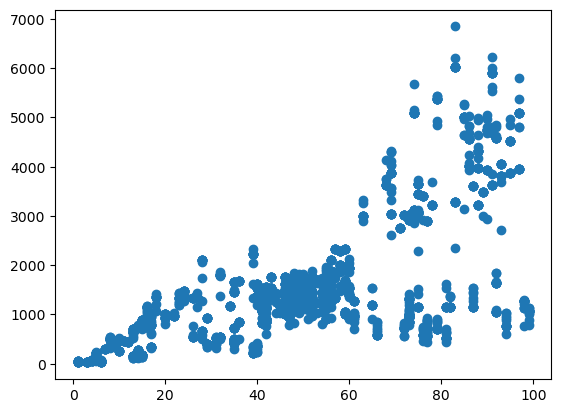

In [11]:
# Check for linearity
plt.scatter(x1,y1)

In [12]:
# Extract the estimated parameters.
print("R-squared value: ", test1.params)

# Extract the standard errors.
print("Standard errors: ", test1.bse)

# Extract the predicted values.
print("Predicted values: ", test1.predict())

R-squared value:  Intercept   -75.052663
x1           33.061693
dtype: float64
Standard errors:  Intercept    45.930554
x1            0.814419
dtype: float64
Predicted values:  [1214.35337415 2602.94449102  123.31749662 ... 2933.56142361  453.93442921
  189.44088314]


In [13]:
# Set the X coefficient and the constant to generate the regression table.
# Set the coefficient to 33.061693 and the constant to -75.052663 to generate the regression table 
y1_pred = (-75.052663) + 33.061693 * turtle['customer_score (1-100)']
# View the output.
y1_pred

0       1214.353364
1       2602.944470
2        123.317495
3       2470.697698
4       1247.415057
           ...     
1995    2206.204154
1996     189.440881
1997    2933.561400
1998     453.934425
1999     189.440881
Name: customer_score (1-100), Length: 2000, dtype: float64

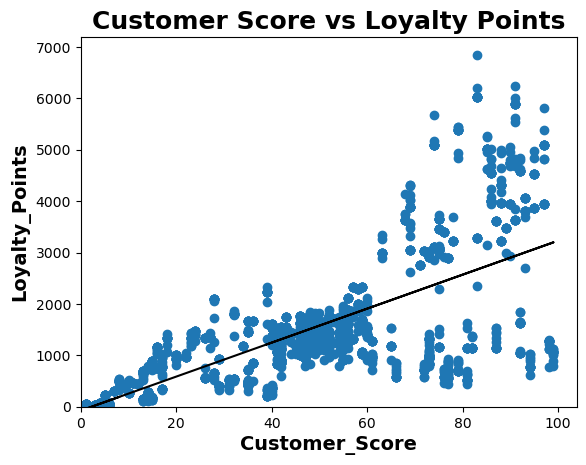

In [14]:
# Plot the data points with a scatterplot

plt.scatter(x1,y1)

# Plot the graph with the regression line (in black)
plt.plot(x1, y1_pred, color='black')

# Set the x and y limits on the axes.
plt.xlim(0)
plt.ylim(0)

# Adding more information to the plot
plt.xlabel('Customer_Score', fontsize=14, fontweight='bold')
plt.ylabel('Loyalty_Points', fontsize=14, fontweight='bold')
plt.title('Customer Score vs Loyalty Points', fontsize= 18, fontweight='bold')

# View the plot
plt.savefig('customer_score_vs_loyalty_points.png', dpi=300)
plt.show()

### 5b) remuneration vs loyalty

In [15]:
turtle

,gender,age,annual_income (k£),customer_score (1-100),loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap
...,...,...,...,...,...,...,...,...,...
1995,Female,37,84.46,69,4031,PhD,977,The perfect word game for mixed ages (with Mom...,The perfect word game for mixed ages (with Mom
1996,Female,43,92.66,8,539,PhD,979,Great game. Did not think I would like it whe...,Super fun
1997,Male,34,92.66,91,5614,graduate,1012,Great game for all.........\nKeeps the mind ni...,Great Game
1998,Male,34,98.40,16,1048,PhD,1031,fun game!,Four Stars


In [16]:
# Define independent variable.

x2 = turtle['annual_income (k£)']
# Define dependent variable.

y2 = turtle['loyalty_points']
# Create model and print summary of metrics.
# Run the OLS test
f2 = 'y2 ~ x2'

test2 = ols(f2, data=turtle).fit()

# View the output

test2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                     y2   R-squared:                       0.380
Model:                            OLS   Adj. R-squared:                  0.379
Method:                 Least Squares   F-statistic:                     1222.
Date:                Sat, 04 Jul 2026   Prob (F-statistic):          2.43e-209
Time:                        22:40:48   Log-Likelihood:                -16674.
No. Observations:                2000   AIC:                         3.335e+04
Df Residuals:                    1998   BIC:                         3.336e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -65.6865     52.171     -1.259      0.208    -168.001      36.628
x2            34.1878      0.978     34.960      0.000      32.270      36.106
==============================================================================
Omnibus:                       21.285   Durbin-Watson:                   3.622
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               31.715
Skew:                           0.089   Prob(JB):                     1.30e-07
Kurtosis:                       3.590   Cond. No.                         123.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [17]:
# Extract the estimated parameters.
print("Parameters: ", test2.params)

# Extract the standard errors.
print("Standard errors: ", test2.bse)

# Extract the predicted values.
print("Predicted values: ", test2.predict())

Parameters:  Intercept   -65.686513
x2           34.187825
dtype: float64
Standard errors:  Intercept    52.170717
x2            0.977925
dtype: float64
Predicted values:  [ 354.82374068  354.82374068  382.85775758 ... 3102.15739671 3298.39551499
 3102.15739671]


In [18]:
# Set the the X coefficient and the constant to generate the regression table.
# Set the coefficient to 34.187825  and the constant to -65.686513 to generate the regression table 
y2_pred = (-65.686513) + 34.187825 * turtle['annual_income (k£)']
# View the output.
y2_pred

0        354.823735
1        354.823735
2        382.857751
3        382.857751
4        410.891767
           ...     
1995    2821.817186
1996    3102.157351
1997    3102.157351
1998    3298.395467
1999    3102.157351
Name: annual_income (k£), Length: 2000, dtype: float64

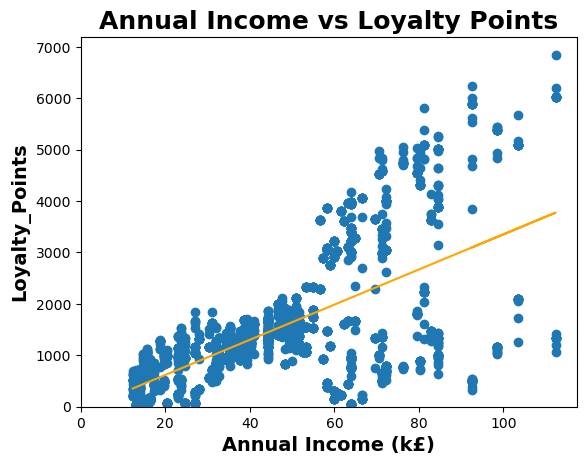

In [19]:
# Plot the data points with a scatterplot

plt.scatter(x2,y2)

# Plot the graph with the regression line (in orange)
plt.plot(x2, y2_pred, color='orange')

# Set the x and y limits on the axes.
plt.xlim(0)
plt.ylim(0)

# Adding more information to the plot
plt.xlabel('Annual Income (k£)', fontsize=14, fontweight='bold')
plt.ylabel('Loyalty_Points', fontsize=14, fontweight='bold')
plt.title('Annual Income vs Loyalty Points', fontsize= 18, fontweight='bold')

# View the plot
plt.savefig('annual_income_vs_loyalty_points.png', dpi=300)
plt.show()

### 5c) age vs loyalty

In [20]:
# Define independent variable.

x3 = turtle['age']
# Define dependent variable.

y3 = turtle['loyalty_points']
# Create model and print summary of metrics.
# Create formula and pass through OLS methods.

f3 = 'y3 ~ x3'
test3 = ols(f3, data= turtle).fit()

# Print the regression table
test3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                     y3   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     3.606
Date:                Sat, 04 Jul 2026   Prob (F-statistic):             0.0577
Time:                        22:40:49   Log-Likelihood:                -17150.
No. Observations:                2000   AIC:                         3.430e+04
Df Residuals:                    1998   BIC:                         3.431e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1736.5177     88.249     19.678      0.000    1563.449    1909.587
x3            -4.0128      2.113     -1.899      0.058      -8.157       0.131
==============================================================================
Omnibus:                      481.477   Durbin-Watson:                   2.277
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              937.734
Skew:                           1.449   Prob(JB):                    2.36e-204
Kurtosis:                       4.688   Cond. No.                         129.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [21]:
# Extract the estimated parameters.
print("Parameters: ", test3.params)

# Extract the standard errors.

print("Standard errors: ", test3.bse)
# Extract the predicted values.
print("Predicted values: ", test3.predict())

Parameters:  Intercept    1736.517739
x3             -4.012805
dtype: float64
Standard errors:  Intercept    88.248731
x3            2.113177
dtype: float64
Predicted values:  [1664.2872467  1644.22322095 1648.2360261  ... 1600.0823643  1600.0823643
 1608.1079746 ]


In [22]:
# Set the X coefficient and the constant to generate the regression table
# Set the coefficient to -4.012805  and the constant to 1736.517739 to generate the regression table 
y3_pred = 1736.517739 - 4.012805 * turtle['age']
# View the output.
y3_pred

0       1664.287249
1       1644.223224
2       1648.236029
3       1636.197614
4       1604.095174
           ...     
1995    1588.043954
1996    1563.967124
1997    1600.082369
1998    1600.082369
1999    1608.107979
Name: age, Length: 2000, dtype: float64

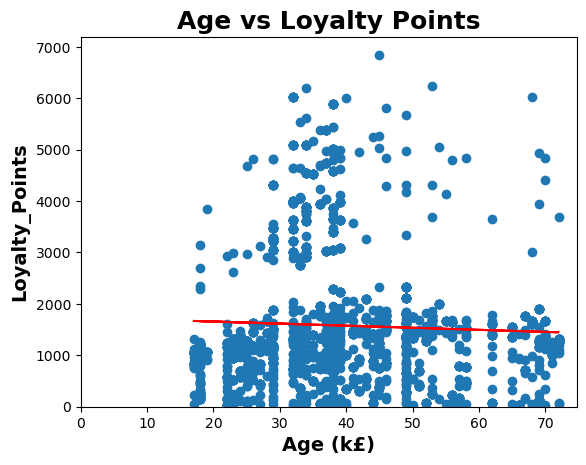

In [23]:
# Plot the data points with a scatterplot

plt.scatter(x3,y3)

# Plot the graph with the regression line (in orange)
plt.plot(x3, y3_pred, color='red')

# Set the x and y limits on the axes.
plt.xlim(0)
plt.ylim(0)

# Adding more information to the plot
plt.xlabel('Age (years)', fontsize=14, fontweight='bold')
plt.ylabel('Loyalty_Points', fontsize=14, fontweight='bold')
plt.title('Age vs Loyalty Points', fontsize= 18, fontweight='bold')

# View the plot
plt.savefig('age_vs_loyalty_points.png', dpi=300)
plt.show()

## 6. Observations and insights

#### Customer Score vs Loyalty Points:
- 45% of the total variability of loyalty points is explained by customer's spending nature and behaviour.
- Strong positive relationship.
- The upward trend is consistent up to a customer score of 60. When the customer score is more than 70, it is shown as the loyalty points they accumulated expands sharply -> this could be understood adding more variables to understand.
- 2 visible groups: 1 group with high customer score and high loyalty points but also 1 group with low customer score yet low loyalty points.
#### Annual Income vs Loyalty Points:
- 38 % of the total variability of loyalty points is explained by annual income of customers.
- Positive correlation.
- When earning more than 60K, customers split into 2 groups: 1 group with high accumulated loyalty points and 1 group with low loyalty points
-> High income does not fully reflect loyalty engagement.
#### Age vs Loyalty Points:
Age barely got any impact or correlation to loyalty points.
-> No predictive power 

#### What could be explored further and suggested future actions.
1. As customer score shows a strong relationship towards loyalty points, I would combine this aspect with other aspects such as annual income in order to build a more effective model.
2. Understanding why there are a group of customer showing high customer score and high income yet low loyalty points -> is there any reason behind this pattern?
To be more specific:
- 55% total variability of loyalty points unexplained by customer score
- 62% total variability of loyalty points unexplained by annual income
-> Many other unseen factors might affect overall loyalty points.
4. Consider removing age from the model as this factor might not be beneficial in optimizing the model.
5. Customer segmentation can be considered

# Part 2: Decision tree regression

## 1. Load and prepare the data

In [24]:
# Import all the necessary packages
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeRegressor, plot_tree 
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
import warnings
import matplotlib.pyplot as plt

# Settings for the notebook.
warnings.filterwarnings("ignore")
plt.rcParams['figure.figsize'] = [15, 10]

In [25]:
# Create your new DataFrame.
df = pd.read_csv('turtle_reviews_new.csv')

# View the DataFrame
df

,gender,age,annual_income (k£),customer_score (1-100),loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap
...,...,...,...,...,...,...,...,...,...
1995,Female,37,84.46,69,4031,PhD,977,The perfect word game for mixed ages (with Mom...,The perfect word game for mixed ages (with Mom
1996,Female,43,92.66,8,539,PhD,979,Great game. Did not think I would like it whe...,Super fun
1997,Male,34,92.66,91,5614,graduate,1012,Great game for all.........\nKeeps the mind ni...,Great Game
1998,Male,34,98.40,16,1048,PhD,1031,fun game!,Four Stars


In [26]:
df['gender'].unique()

array(['Male', 'Female'], dtype=object)

### Transform categorical string values to numeric values for modelling

#### Gender column

Decided to make changes in the 'gender' column to change from current string values to numeric values for modelling:
+ 'Male' replaced by 1
+ 'Female' replaced by 0

In [27]:
# Update the gender column with male = 1, and female = 0
df['gender'] = df['gender'].map({'Male':1, 'Female':0})

# View the output
df

,gender,age,annual_income (k£),customer_score (1-100),loyalty_points,education,product,review,summary
0,1,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,1,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,0,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,0,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,0,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap
...,...,...,...,...,...,...,...,...,...
1995,0,37,84.46,69,4031,PhD,977,The perfect word game for mixed ages (with Mom...,The perfect word game for mixed ages (with Mom
1996,0,43,92.66,8,539,PhD,979,Great game. Did not think I would like it whe...,Super fun
1997,1,34,92.66,91,5614,graduate,1012,Great game for all.........\nKeeps the mind ni...,Great Game
1998,1,34,98.40,16,1048,PhD,1031,fun game!,Four Stars


#### Education column

The education levels follow a natural low-to-high order, decided to change from string values to numeric values. In particular:

+ "Basic" : 0
+ "Diploma": 1
+ Graduate": 2
+ "Postgraduate": 3
+ "PhD": 4

In [28]:
df['education'].value_counts()

education
graduate        900
PhD             460
postgraduate    400
diploma         190
Basic            50
Name: count, dtype: int64

In [29]:
df['education'].unique().tolist()

['graduate', 'PhD', 'diploma', 'postgraduate', 'Basic']

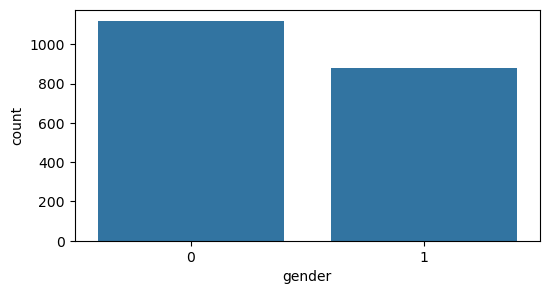

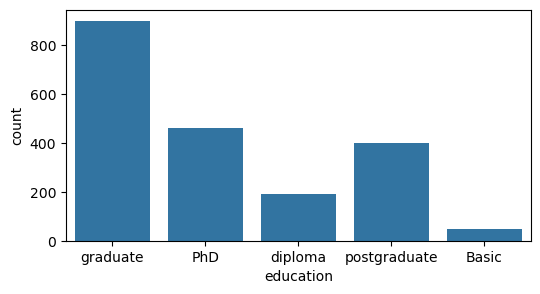

In [30]:
# Plot graph for individual columns to understand the distribution
# Gender male = 1, and female = 0 
plt.rcParams['figure.figsize'] = [6, 3]
sns.countplot(x=df['gender'])
plt.show()
sns.countplot(x=df['education'])
plt.show()

In [31]:
# Update the education column: "Basic" = 0, "Diploma" = 1, "Graduate" = 2, "Postgraduate" = 3, "PhD" = 4
df['education'] = df['education'].map({'Basic':0, 'diploma':1,
                                       'graduate':2,'postgraduate':3, 'PhD':4})

# View the output
df

,gender,age,annual_income (k£),customer_score (1-100),loyalty_points,education,product,review,summary
0,1,18,12.30,39,210,2,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,1,23,12.30,81,524,2,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,0,22,13.12,6,40,2,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,0,25,13.12,77,562,2,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,0,33,13.94,40,366,2,291,As my review of GF9's previous screens these w...,Money trap
...,...,...,...,...,...,...,...,...,...
1995,0,37,84.46,69,4031,4,977,The perfect word game for mixed ages (with Mom...,The perfect word game for mixed ages (with Mom
1996,0,43,92.66,8,539,4,979,Great game. Did not think I would like it whe...,Super fun
1997,1,34,92.66,91,5614,2,1012,Great game for all.........\nKeeps the mind ni...,Great Game
1998,1,34,98.40,16,1048,4,1031,fun game!,Four Stars


In [32]:
df.columns.tolist()

['gender',
 'age',
 'annual_income (k£)',
 'customer_score (1-100)',
 'loyalty_points',
 'education',
 'product',
 'review',
 'summary']

In [33]:
# Specify Y.
y = df['loyalty_points']
# Specify X.
cols = ['gender','age','annual_income (k£)','customer_score (1-100)']
# cols1 = ['age','annual_income (k£)','customer_score (1-100)']
X = df[cols]

In [34]:
# Review X and Y.
X.shape, y.shape

((2000, 4), (2000,))

## 2. Create train and test data sets.

In [35]:
# Split the data into test and train data.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.3, random_state= 42)

In [36]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((1400, 4), (1400,), (600, 4), (600,))

## 3. Create Decision tree regressor

In [37]:
# Create your decision tree regressor.
from sklearn import tree
my_tree = DecisionTreeRegressor(random_state=42, max_depth=7)

# Train the Decision Tree Regressor
reg = my_tree.fit(X_train, y_train)

# Predict the response for the dataset
y_pred = reg.predict(X_test)

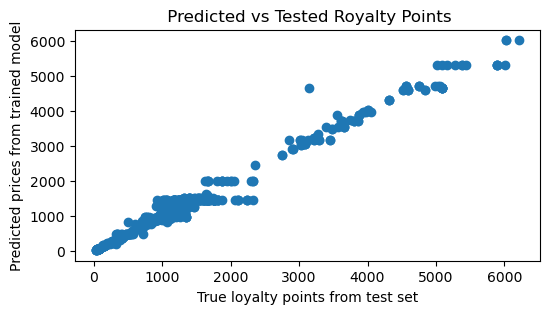

In [38]:
# Scatter plot for predicted and tested value
plt.scatter(y_test, y_pred)
plt.xlabel("True loyalty points from test set")
plt.ylabel("Predicted loyalty points")
plt.title("Predicted vs Actual Loyalty Points")
plt.savefig('decision_tree_regression_1.png', dpi=300)
plt.show()

In [39]:
# Getting mean absolute error
from sklearn.metrics import mean_absolute_error as MAE
err = MAE(y_test, y_pred)
print("Mean absolute error of test set is: ", err)

Mean absolute error of test set is:  118.69835460806895


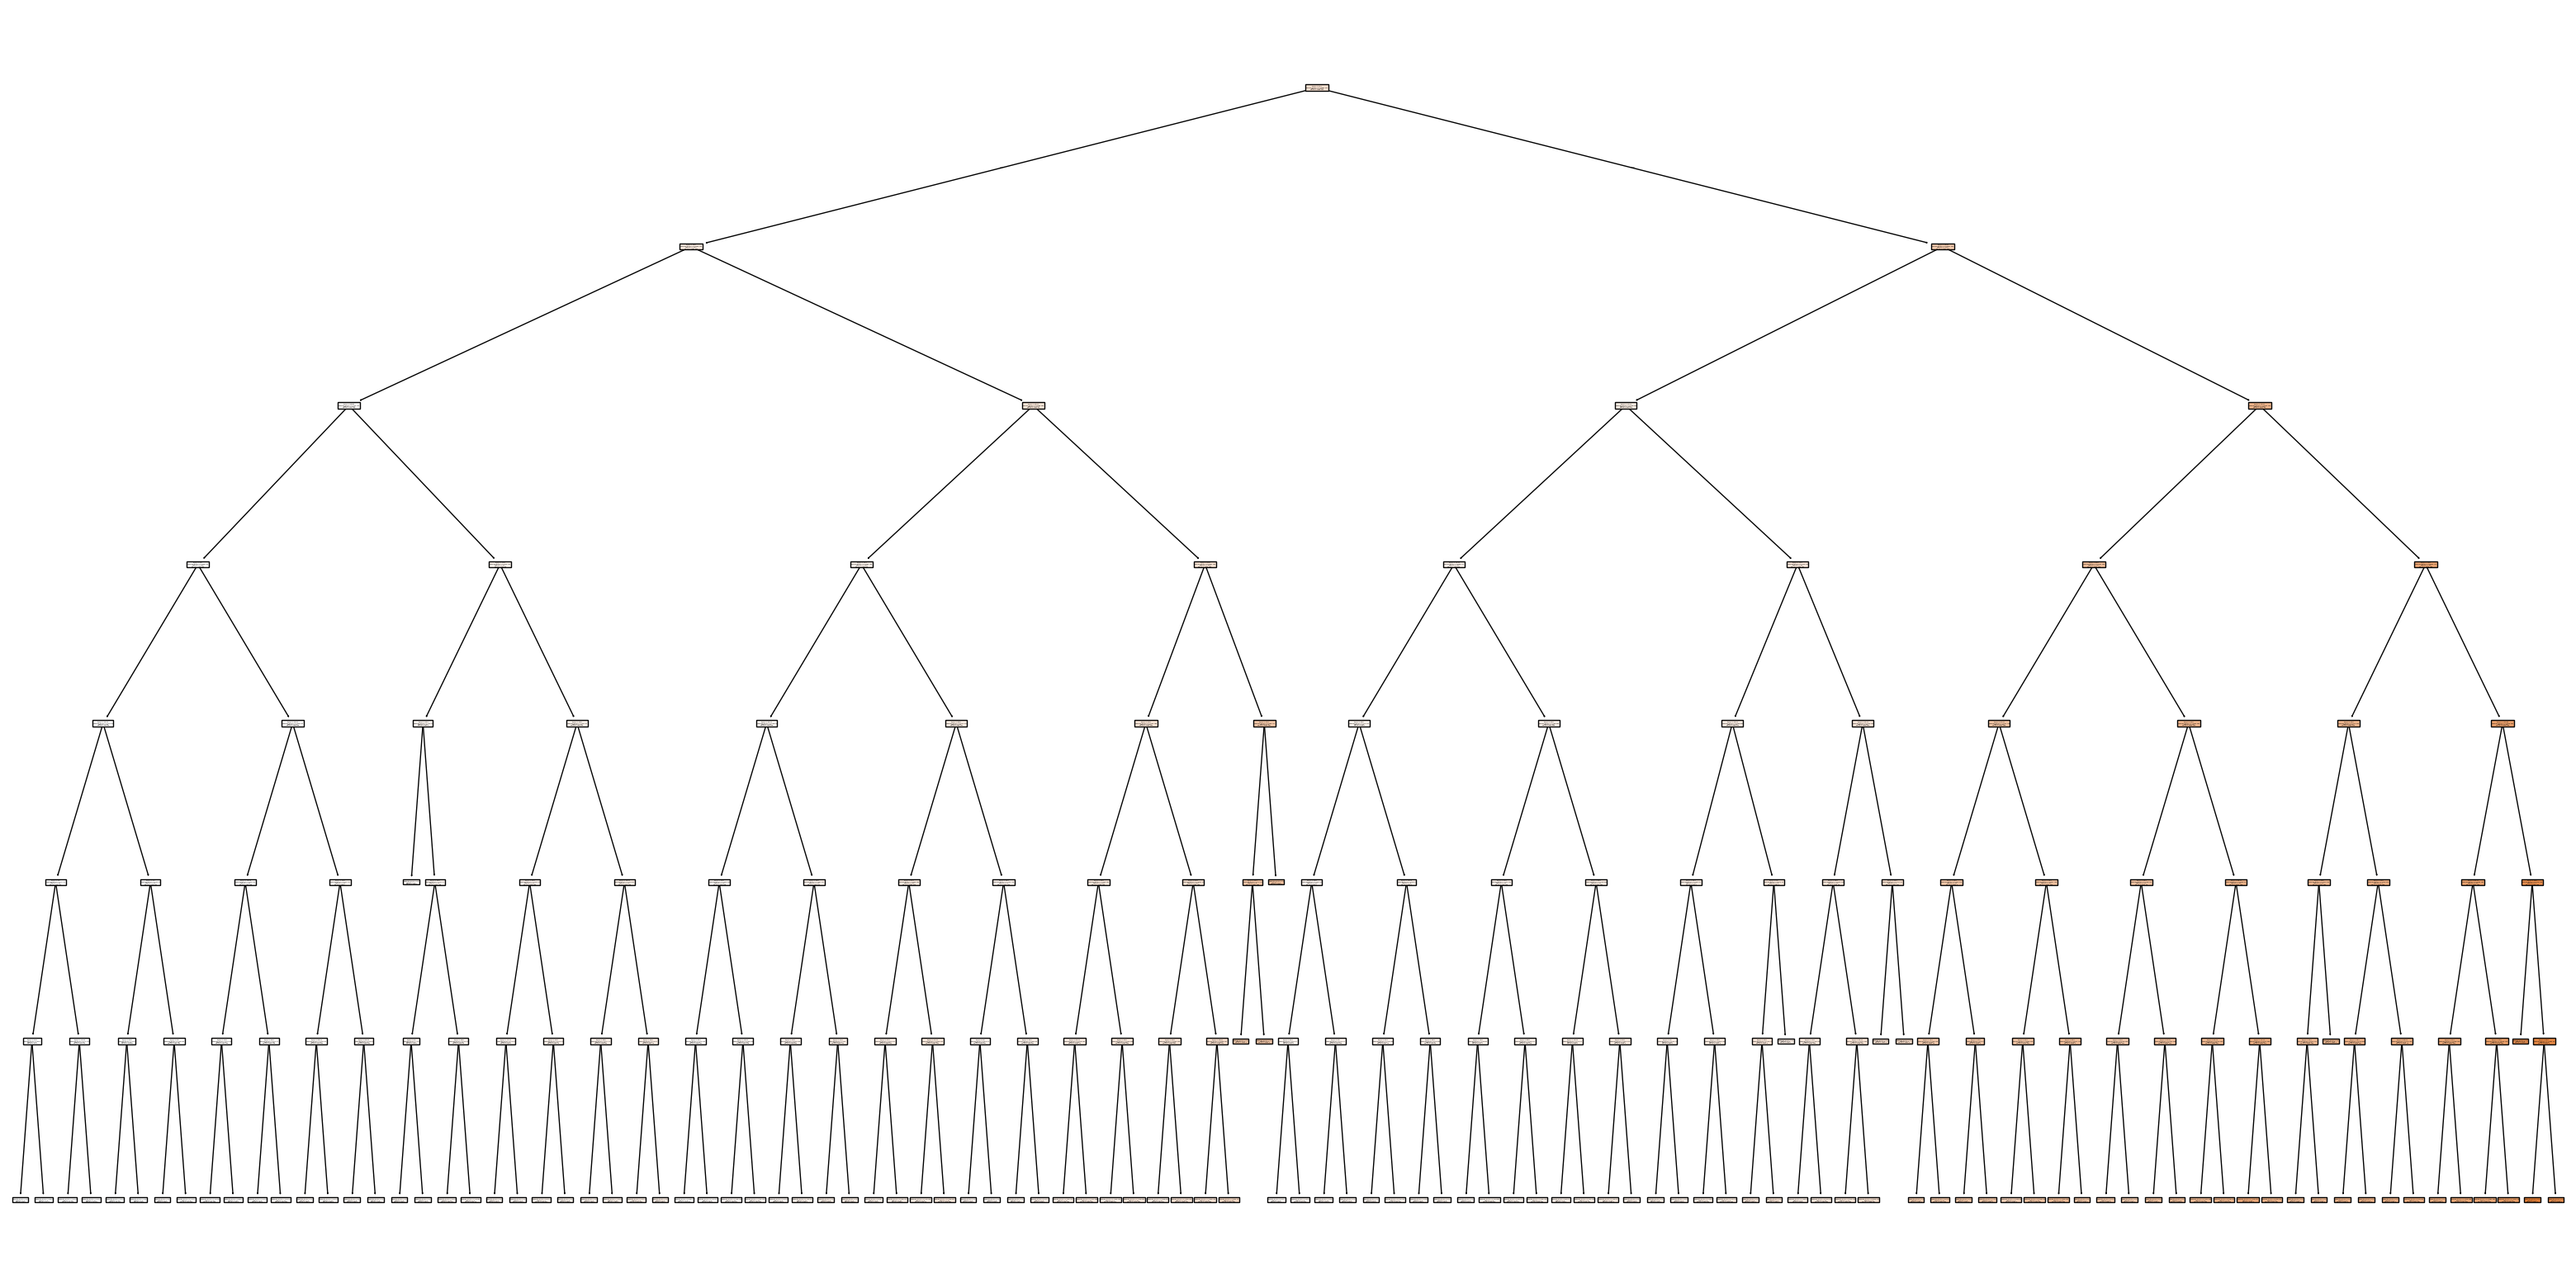

In [40]:
# Plot the tree
plt.figure(figsize=(40, 20)) 
tree.plot_tree(reg, filled=True)
plt.savefig('decision_tree_regressor_2.png', dpi=800)

#### Evaluate the model (MAE, MSE, RMSE and R²)

In [41]:
accuracy = pd.DataFrame({'Actual Value': y_test, 'Predicted Values': y_pred})  
print(accuracy)

print('Mean Absolute Error:', metrics.mean_absolute_error(y_test, y_pred))
print('Mean Squared Error:', metrics.mean_squared_error(y_test, y_pred))
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

      Actual Value  Predicted Values
1860            59         71.916667
353           3398       3540.428571
1333          2750       2750.000000
905           1122       1276.461538
1289          1622       1464.713855
...            ...               ...
148            962        987.276596
1554          5023       4704.823529
1956          1459       1464.713855
925           2900       2904.545455
942           1609       1464.713855

[600 rows x 2 columns]
Mean Absolute Error: 118.69835460806895
Mean Squared Error: 36645.44461056044
Root Mean Squared Error: 191.42999924400678


In [42]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)
print(f'R² Score: {r2:.4f}')
print(f'R² as a percentage: {r2 * 100:.2f}%')

R² Score: 0.9774
Accuracy: 97.74%


### Scenario 2: Test using variables with 3 columns only: age, customer_score, annual income

In [43]:
# Specify y.
y1 = df['loyalty_points']
# Specify X.
cols1 = ['age','annual_income (k£)','customer_score (1-100)']
X1 = df[cols1]

print(X1)
print(y1)

      age  annual_income (k£)  customer_score (1-100)
0      18               12.30                      39
1      23               12.30                      81
2      22               13.12                       6
3      25               13.12                      77
4      33               13.94                      40
...   ...                 ...                     ...
1995   37               84.46                      69
1996   43               92.66                       8
1997   34               92.66                      91
1998   34               98.40                      16
1999   32               92.66                       8

[2000 rows x 3 columns]
0        210
1        524
2         40
3        562
4        366
        ... 
1995    4031
1996     539
1997    5614
1998    1048
1999     479
Name: loyalty_points, Length: 2000, dtype: int64


In [44]:
# Split the data into test and train data.
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size= 0.3, random_state= 42)

X1_train.shape, y1_train.shape, X1_test.shape, y1_test.shape

((1400, 3), (1400,), (600, 3), (600,))

In [45]:
# Create your decision tree regressor.
from sklearn import tree
my_tree_1 = DecisionTreeRegressor(random_state=42, max_depth=7)

# Train the Decision Tree Regressor
reg_1 = my_tree_1.fit(X1_train, y1_train)

# Predict the response for the dataset
y1_pred = reg_1.predict(X1_test)

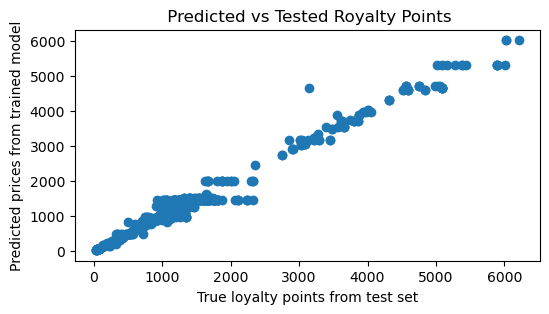

In [46]:
# Scatter plot for predicted and tested value
plt.scatter(y1_test, y1_pred)
plt.xlabel("True loyalty points from test set")
plt.ylabel("Predicted loyalty points")
plt.title("Predicted vs Actual Loyalty Points")
plt.savefig('decision_tree_regression_3.png', dpi=300)
plt.show()

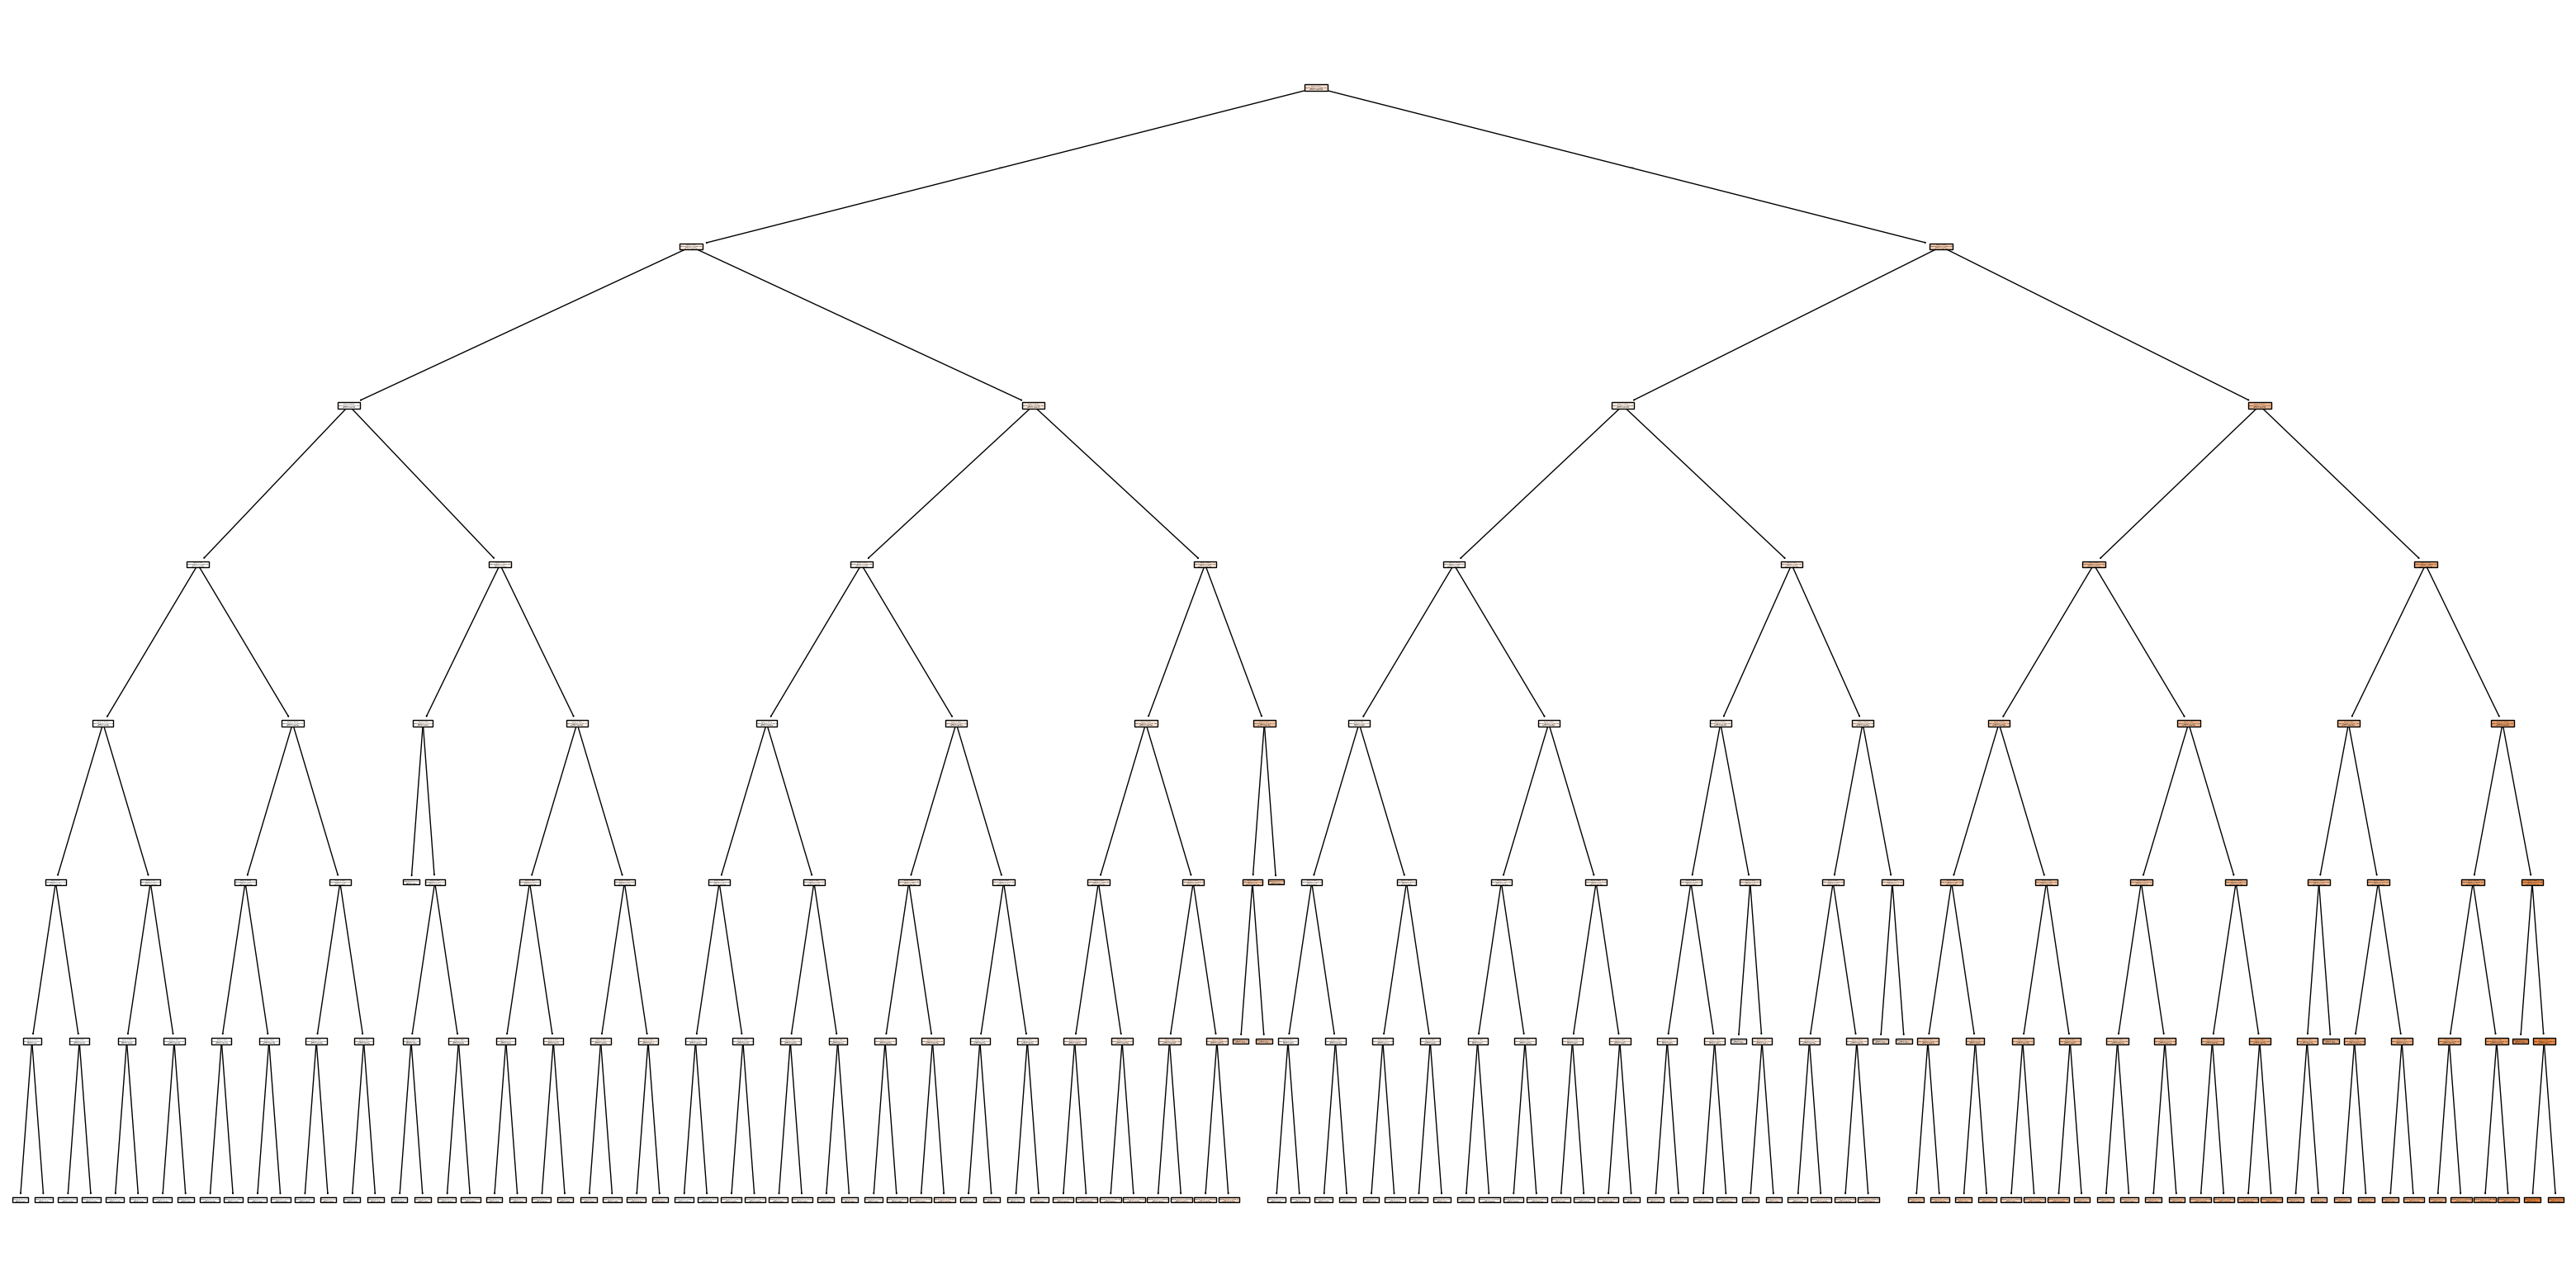

In [47]:
# Plot the tree
plt.figure(figsize=(40, 20)) 
tree.plot_tree(reg_1, filled=True)
plt.savefig('decision_tree_regressor_4.png', dpi=800)

In [48]:
accuracy_1 = pd.DataFrame({'Actual Value': y1_test, 'Predicted Values': y1_pred})  
print(accuracy_1)

print('Mean Absolute Error:', metrics.mean_absolute_error(y1_test, y1_pred))
print('Mean Squared Error:', metrics.mean_squared_error(y1_test, y1_pred))
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y1_test, y1_pred)))

      Actual Value  Predicted Values
1860            59         71.916667
353           3398       3540.428571
1333          2750       2750.000000
905           1122       1276.461538
1289          1622       1464.713855
...            ...               ...
148            962        987.276596
1554          5023       4704.823529
1956          1459       1464.713855
925           2900       2904.545455
942           1609       1464.713855

[600 rows x 2 columns]
Mean Absolute Error: 119.1129379414023
Mean Squared Error: 36702.55466264377
Root Mean Squared Error: 191.57910810587822


In [49]:
from sklearn.metrics import r2_score

r2_1 = r2_score(y1_test, y1_pred)
print(f'R² Score: {r2_1:.4f}')
print(f'Accuracy: {r2_1 * 100:.2f}%')

R² Score: 0.9773
Accuracy: 97.73%


### Scenario 3: Test using variables with 2 columns only: customer_score, annual income

In [50]:
# Specify y.
y2 = df['loyalty_points']
# Specify X.
cols2 = ['annual_income (k£)','customer_score (1-100)']
X2 = df[cols2]

print(X2)
print(y2)

      annual_income (k£)  customer_score (1-100)
0                  12.30                      39
1                  12.30                      81
2                  13.12                       6
3                  13.12                      77
4                  13.94                      40
...                  ...                     ...
1995               84.46                      69
1996               92.66                       8
1997               92.66                      91
1998               98.40                      16
1999               92.66                       8

[2000 rows x 2 columns]
0        210
1        524
2         40
3        562
4        366
        ... 
1995    4031
1996     539
1997    5614
1998    1048
1999     479
Name: loyalty_points, Length: 2000, dtype: int64


In [51]:
# Split the data into test and train data.
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size= 0.3, random_state= 42)

X2_train.shape, y2_train.shape, X2_test.shape, y2_test.shape

((1400, 2), (1400,), (600, 2), (600,))

In [52]:
# Create your decision tree regressor.
from sklearn import tree
my_tree_2 = DecisionTreeRegressor(random_state=42, max_depth=7)

# Train the Decision Tree Regressor
reg_2 = my_tree_2.fit(X2_train, y2_train)

# Predict the response for the dataset
y2_pred = reg_2.predict(X2_test)

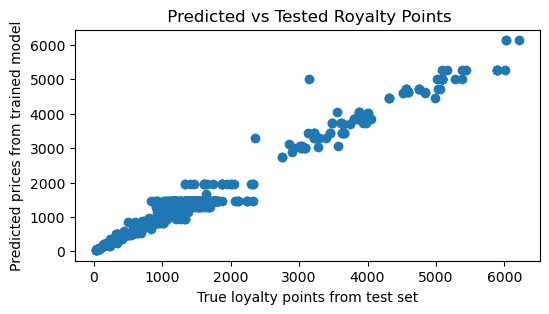

In [53]:
# Scatter plot for predicted and tested value
plt.scatter(y2_test, y2_pred)
plt.xlabel("True loyalty points from test set")
plt.ylabel("Predicted loyalty points")
plt.title("Predicted vs Actual Loyalty Points")
plt.savefig('decision_tree_regression_5.png', dpi=300)
plt.show()

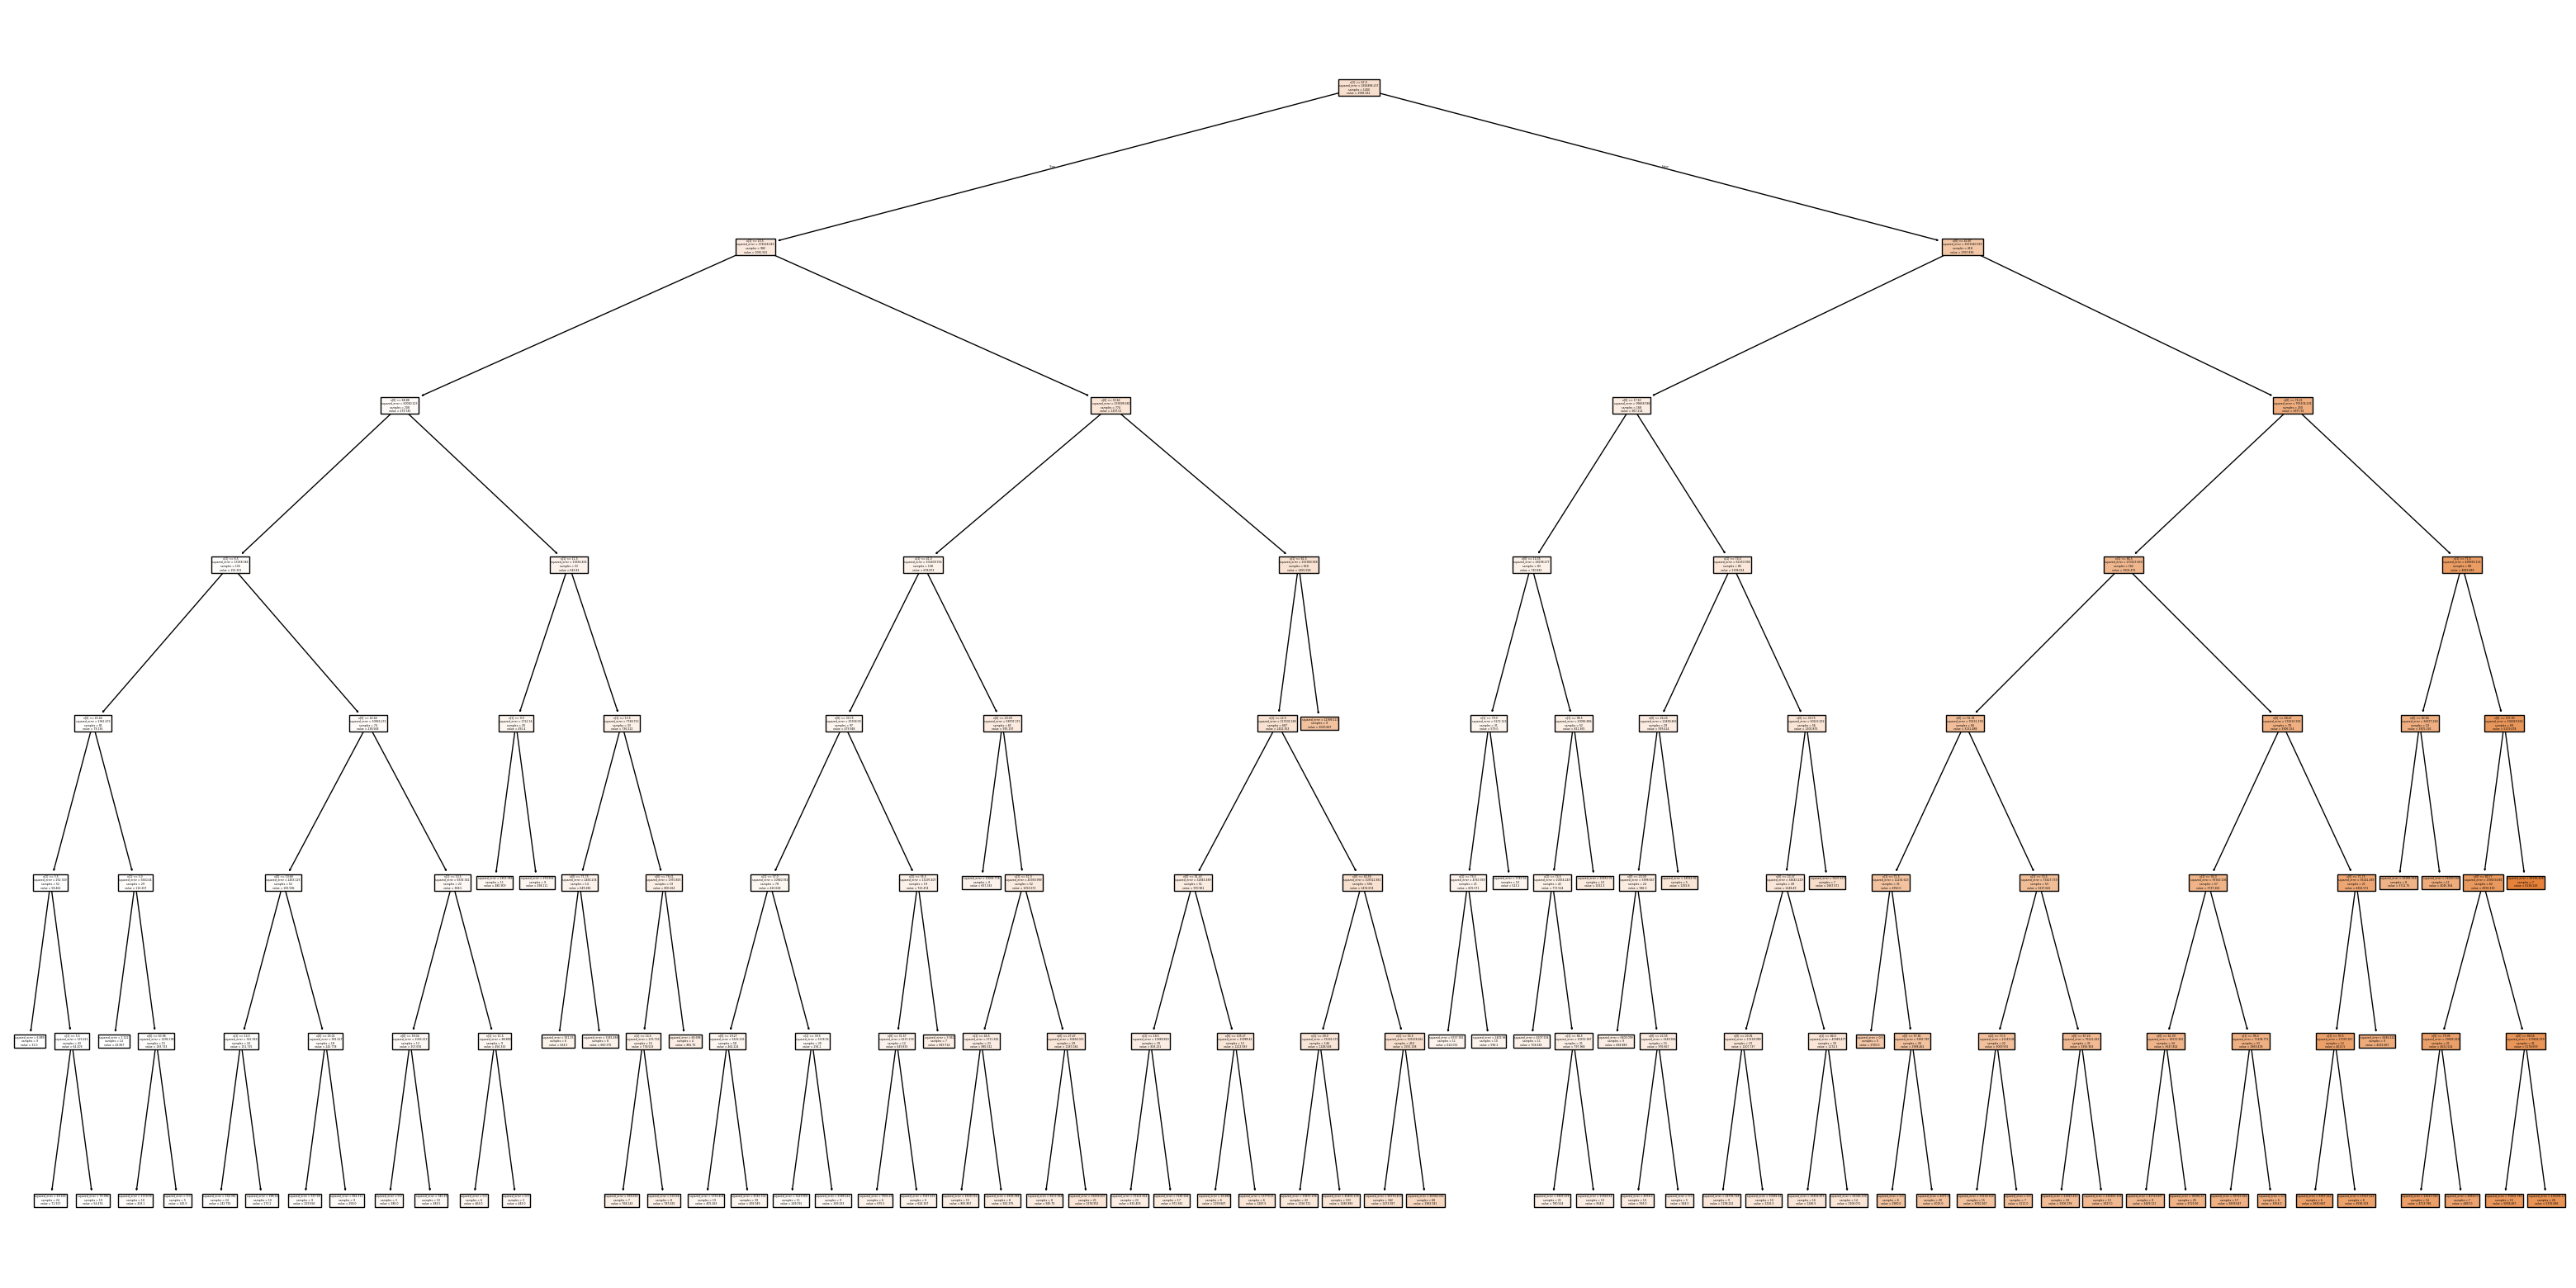

In [54]:
# Plot the tree
plt.figure(figsize=(40,20)) 
tree.plot_tree(reg_2, filled=True)
plt.savefig('decision_tree_regressor_6.png', dpi=800)

In [55]:
accuracy_2 = pd.DataFrame({'Actual Value': y2_test, 'Predicted Values': y2_pred})  
print(accuracy_2)

print('Mean Absolute Error:', metrics.mean_absolute_error(y2_test, y2_pred))
print('Mean Squared Error:', metrics.mean_squared_error(y2_test, y2_pred))
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y2_test, y2_pred)))

      Actual Value  Predicted Values
1860            59         71.916667
353           3398       3306.277778
1333          2750       2750.000000
905           1122       1473.926901
1289          1622       1473.926901
...            ...               ...
148            962        971.941176
1554          5023       4713.785714
1956          1459       1473.926901
925           2900       2900.000000
942           1609       1473.926901

[600 rows x 2 columns]
Mean Absolute Error: 142.54551543755727
Mean Squared Error: 48322.42888448034
Root Mean Squared Error: 219.8236313149256


In [56]:
from sklearn.metrics import r2_score

r2_2 = r2_score(y2_test, y2_pred)
print(f'R² Score: {r2_2:.4f}')
print(f'Accuracy: {r2_2 * 100:.2f}%')

R² Score: 0.9702
Accuracy: 97.02%


#### Interpret model and note observations.
- Results when testing with 4 columns: age, gender, customer_Score, income, max_depth=7

R²: 97.74%

- Result when testing with 3 columns: age, customer_score, income, max_depth = 7

R²: 97.73%

- Result when testing with 2 columns: customer_score, income, max_depth = 7

R²: 97.02%

The depth of 7 gives a high R², will try with different max depth length later to decide how to prune the tree

## 4. Fit and plot final model.

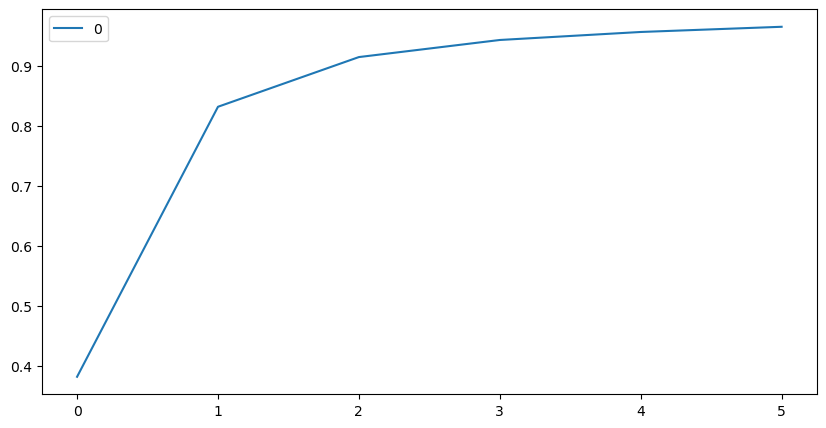

In [57]:
# Prune the model.
# Determine the optimal value for max depth, then prune the decision tree
# One approach often applied is to look at a range of values for the parameter under investigation

# List of values to try for max_depth:
max_depth_range = list(range(1, 7))

# have a loop that fits decision trees for different 'max_depth', and calculate/store the R² of each tree
accuracy_3 = []
for depth in max_depth_range:    
    reg_3 = DecisionTreeRegressor(max_depth = depth, random_state = 0)
    reg_3.fit(X_train, y_train)
    score = reg_3.score(X_test, y_test)
    accuracy_3.append(score)
    
# Plot R² values across the range of depth values evaluated
plt.rcParams['figure.figsize'] = [10, 5]
accuracy_3 = pd.DataFrame(accuracy_3)
accuracy_3.plot()
plt.show()

In [58]:
# Split the data into test and train data.
X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(X, y, test_size= 0.3, random_state= 42)

X_train_final.shape, y_train_final.shape, X_test_final.shape, y_test_final.shape

((1400, 4), (1400,), (600, 4), (600,))

In [59]:
# Fit and plot final model.
# Create your decision tree regressor.
from sklearn import tree
my_tree_final= DecisionTreeRegressor(random_state=42, max_depth=3)

# Train the Decision Tree Regressor
reg_final = my_tree_final.fit(X_train_final, y_train_final)

# Predict the response for the dataset
y_pred_final = reg.predict(X_test_final)

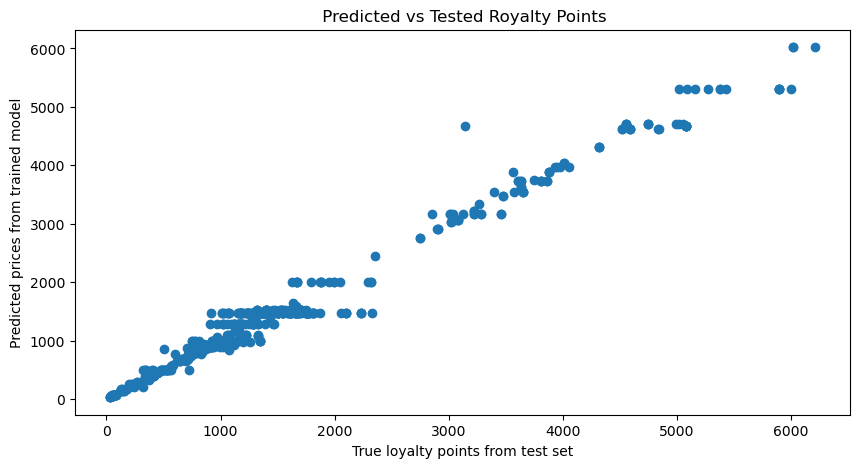

In [60]:
# Scatter plot for predicted and tested value
plt.scatter(y_test_final, y_pred_final)
plt.xlabel("True loyalty points from test set")
plt.ylabel("Predicted loyalty points")
plt.title("Predicted vs Actual Loyalty Points")
plt.savefig('decision_tree_regression_3.png', dpi=300)
plt.show()

Tree depth = 3 
Number of leaves = 8
R² Score: 0.9774
Accuracy: 97.74%


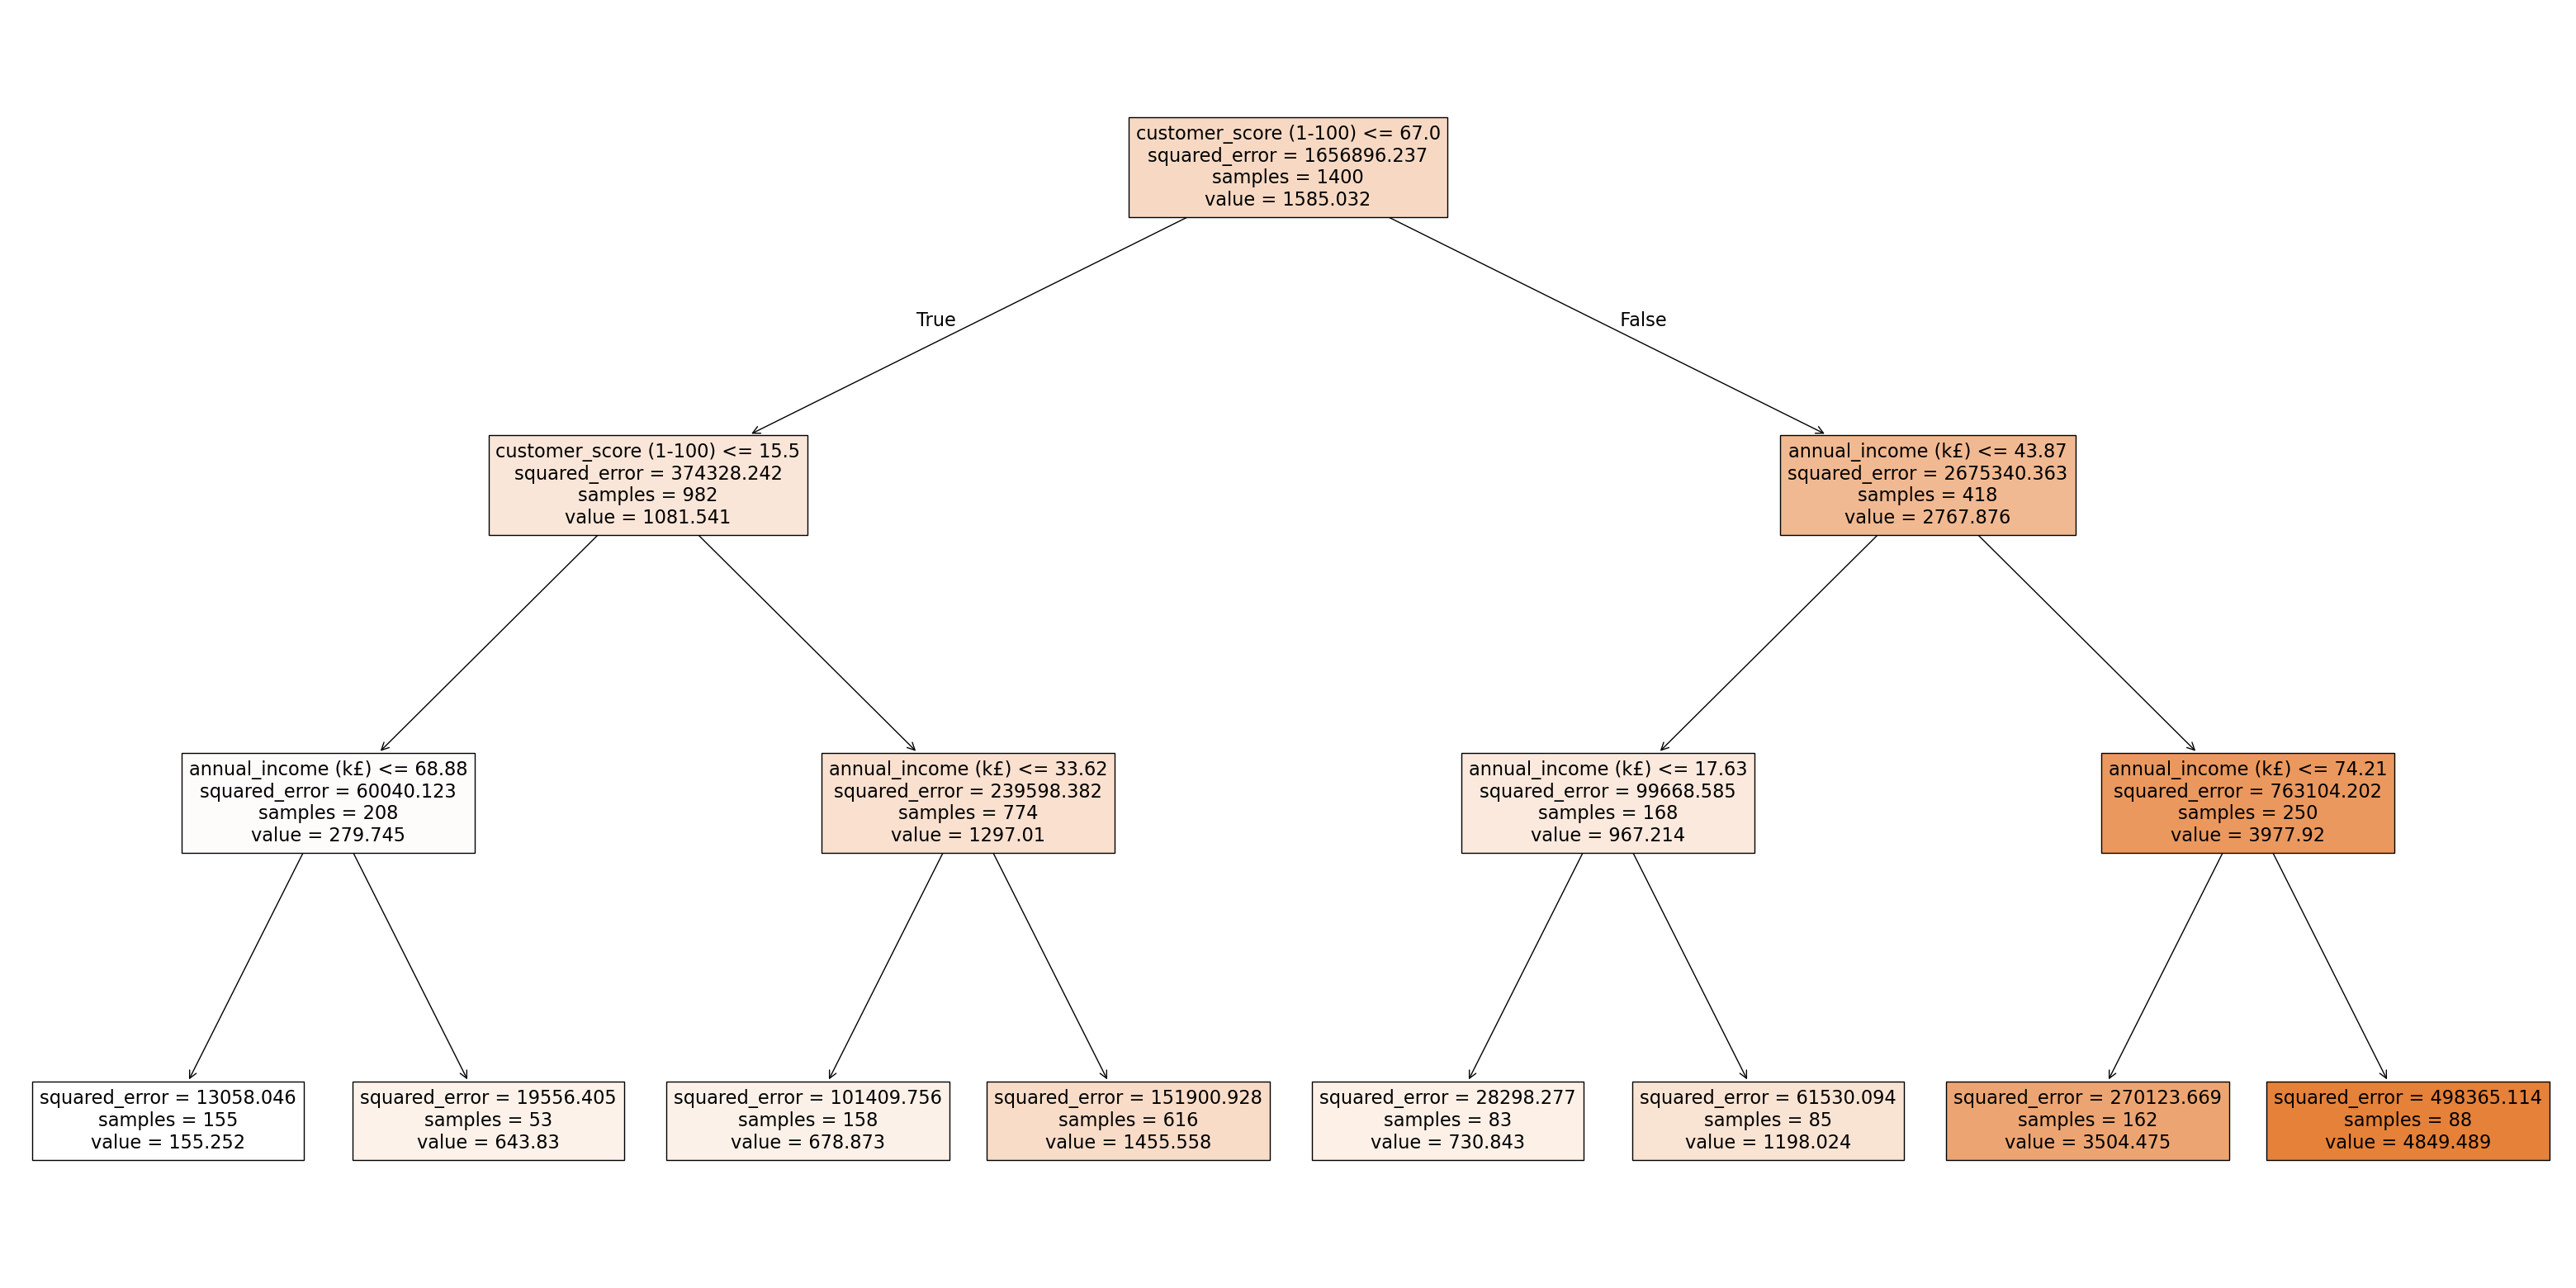

In [61]:
# Plot the tree
plt.figure(figsize=(40,20)) 
tree.plot_tree(reg_final, feature_names=cols, filled=True)
plt.savefig('decision_tree_regressor_final.png', dpi=800)

print("Tree depth =", reg_final.get_depth(),'\n'
      "Number of leaves =", reg_final.get_n_leaves())

from sklearn.metrics import r2_score

r2_final = r2_score(y_test_final, y_pred_final)
print(f'R² Score: {r2_final:.4f}')
print(f'Accuracy: {r2_final * 100:.2f}%')

In [62]:
# Finding out about Feature importance to help in the decision making process
reg_input = reg_final
importances = pd.DataFrame({'feature':X_train_final.columns,'importance':np.round(reg_input.feature_importances_,3)})
importances = importances.sort_values('importance',ascending=False)
importances

,feature,importance
2,annual_income (k£),0.525
3,customer_score (1-100),0.475
0,gender,0.000
1,age,0.000


In [63]:
accuracy_final = pd.DataFrame({'Actual Value': y_test_final, 'Predicted Values': y_pred_final})  
print(accuracy_final)

print('Mean Absolute Error:', metrics.mean_absolute_error(y_test_final, y_pred_final))
print('Mean Squared Error:', metrics.mean_squared_error(y_test_final, y_pred_final))
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y_test_final, y_pred_final)))

      Actual Value  Predicted Values
1860            59         71.916667
353           3398       3540.428571
1333          2750       2750.000000
905           1122       1276.461538
1289          1622       1464.713855
...            ...               ...
148            962        987.276596
1554          5023       4704.823529
1956          1459       1464.713855
925           2900       2904.545455
942           1609       1464.713855

[600 rows x 2 columns]
Mean Absolute Error: 118.69835460806895
Mean Squared Error: 36645.44461056044
Root Mean Squared Error: 191.42999924400678


## 5. Insights and observations

#### Interpret model and note observations.

At first, I studied all variables possible: gender, age, customer score and, annual income. However, by plotting the trees using different variables combinations, seeing statistical results, and understanding the importance of each variable in the tree model, my findings would be:

- Only 2 features actually have an impact on loyalty points: annual income and customer score:
+ annual income slightly affects more than the other: 52.5%
+ customer score: 47.5%
- Gender and age are irrelevant in this case as they showed zero predictive power, the result of the predictive model with or without their presence remains unchanged

-> We should be targeting to understand how customer score and annual income might affect loyalty points, and demographics such as gender and age play no important role in defining loyalty points.

### Decision Tree Analysis

- The tree decision making process was based entirely on customer score and annual income, no gender or age was used as they do not have predictive power.
- Value: loyalty points prediction
- Root node: customer score <=67, 1400 training samples split into 982 low score (<=67), and 418 high score (>67)
+ customer score above 67: loyalty points 2767
+ customer score less than 67: loyalty points 1081
-> Customers with higher scores earn on average 2.5 times more loyalty points than those with scores less than 67.
- Highest score customer(customer score above 67) with highest income (more than 74k) earns around 4,849 points: this can be considered the most valuable customer segment.
- The pruned tree (max depth 3) splits customers into 8 groups based on a combination of income and customer score.
 
-> Suggestion: any loyalty program should focus on encouraging customer to increase their scores and targeting on higher income brackets.

# Part 3: Customer segmentation with k-means clustering

## 1. Load and explore the data

In [64]:
# Import necessary libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import accuracy_score
from scipy.spatial.distance import cdist

import warnings
warnings.filterwarnings('ignore')

In [65]:
# Load the CSV file(s) as df2.
df2= pd.read_csv('turtle_reviews_new.csv')

# View DataFrame.
df2
df2.columns.tolist()

['gender',
 'age',
 'annual_income (k£)',
 'customer_score (1-100)',
 'loyalty_points',
 'education',
 'product',
 'review',
 'summary']

In [66]:
df2

,gender,age,annual_income (k£),customer_score (1-100),loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap
...,...,...,...,...,...,...,...,...,...
1995,Female,37,84.46,69,4031,PhD,977,The perfect word game for mixed ages (with Mom...,The perfect word game for mixed ages (with Mom
1996,Female,43,92.66,8,539,PhD,979,Great game. Did not think I would like it whe...,Super fun
1997,Male,34,92.66,91,5614,graduate,1012,Great game for all.........\nKeeps the mind ni...,Great Game
1998,Male,34,98.40,16,1048,PhD,1031,fun game!,Four Stars


In [67]:
# Drop unnecessary columns.
df3 = df2[['annual_income (k£)','customer_score (1-100)','gender', 'education']]
# View DataFrame.
df3

,annual_income (k£),customer_score (1-100),gender,education
0,12.30,39,Male,graduate
1,12.30,81,Male,graduate
2,13.12,6,Female,graduate
3,13.12,77,Female,graduate
4,13.94,40,Female,graduate
...,...,...,...,...
1995,84.46,69,Female,PhD
1996,92.66,8,Female,PhD
1997,92.66,91,Male,graduate
1998,98.40,16,Male,PhD


In [68]:
# Explore the data.
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   annual_income (k£)      2000 non-null   float64
 1   customer_score (1-100)  2000 non-null   int64  
 2   gender                  2000 non-null   object 
 3   education               2000 non-null   object 
dtypes: float64(1), int64(1), object(2)
memory usage: 62.6+ KB


In [69]:
# Descriptive statistics.
df3.describe()

,annual_income (k£),customer_score (1-100)
count,2000.000000,2000.000000
mean,48.079060,50.000000
std,23.123984,26.094702
min,12.300000,1.000000
25%,30.340000,32.000000
50%,47.150000,50.000000
75%,63.960000,73.000000
max,112.340000,99.000000


## 2. Plot

<Axes: xlabel='annual_income (k£)', ylabel='customer_score (1-100)'>

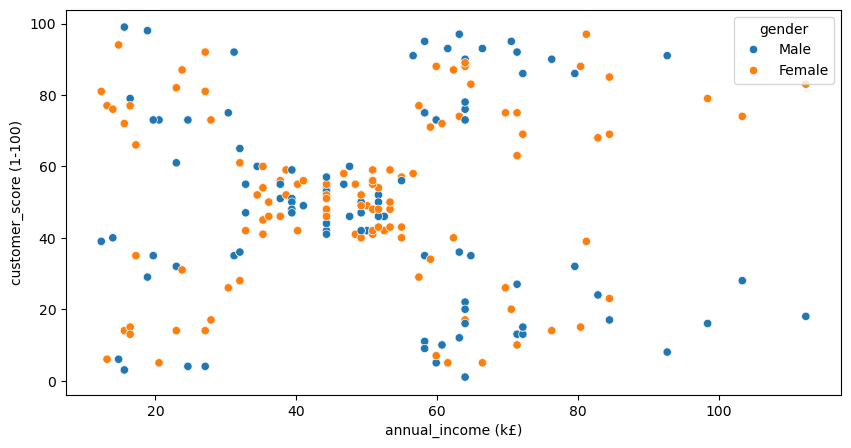

In [70]:
# Create a scatterplot with Seaborn, using gender=hue

sns.scatterplot(x='annual_income (k£)', y='customer_score (1-100)', hue='gender',data=df3)

<Axes: xlabel='annual_income (k£)', ylabel='customer_score (1-100)'>

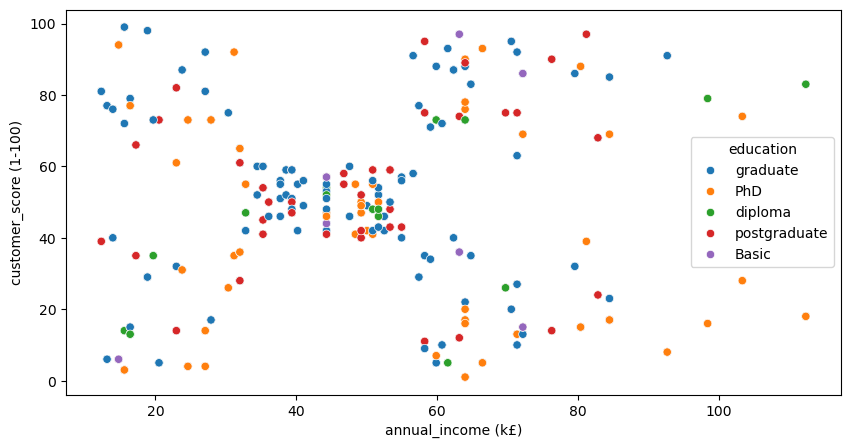

In [71]:
# Create a scatterplot with Seaborn, using gender=education

sns.scatterplot(x='annual_income (k£)', y='customer_score (1-100)', hue='education',data=df3)

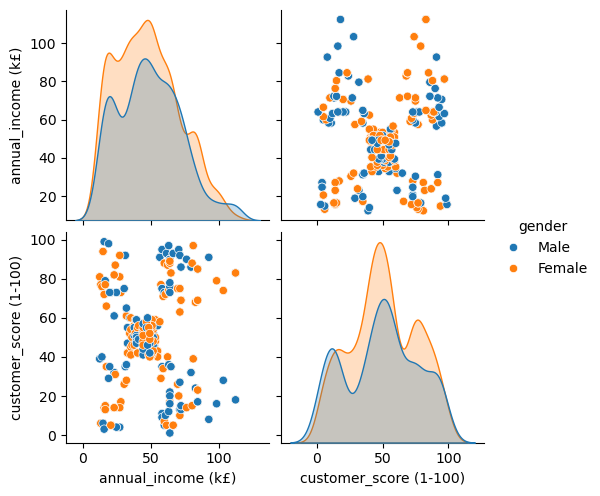

In [72]:
# Create a pairplot with Seaborn using hue='gender'

x= df3[['annual_income (k£)', 'customer_score (1-100)']]
sns.pairplot(df3, vars=x, hue='gender', diag_kind='kde')

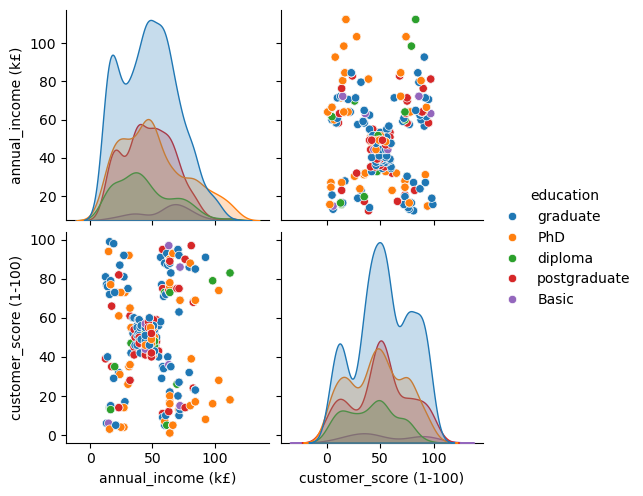

In [73]:
# Create a pairplot with Seaborn using hue='education'

x= df3[['annual_income (k£)', 'customer_score (1-100)']]
sns.pairplot(df3, vars=x, hue='education', diag_kind='kde')

## 3. Elbow and silhouette methods

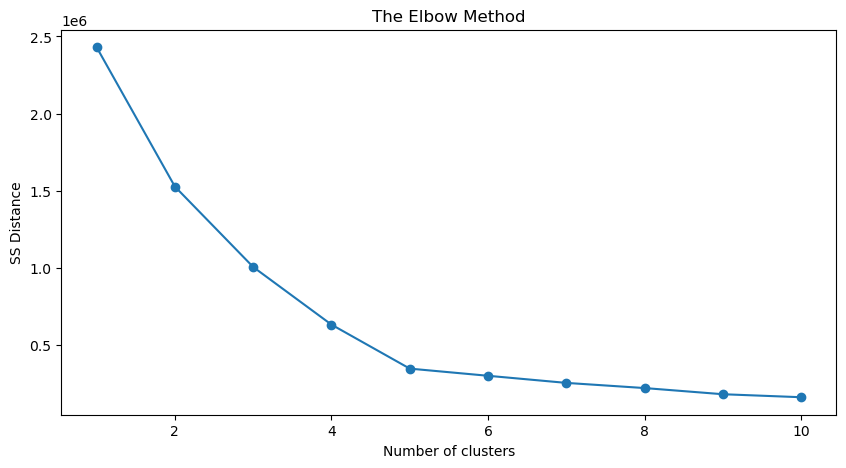

In [74]:
# Determine the number of clusters: Elbow method.
ss= []
for i in range(1,11):
    kmeans= KMeans(n_clusters=i,
                   init='k-means++',
                   max_iter=300,
                   n_init=10,
                   random_state=0)
    kmeans.fit(x)
    ss.append(kmeans.inertia_)

# Plot the elbow method: Plot the sum of squared distances from each point to its assigned centre

plt.plot(range(1,11), ss, marker='o')

# Insert labels and title
plt.title("The Elbow Method")
plt.xlabel("Number of clusters")
plt.ylabel("SS Distance")
plt.savefig('elbow_method.png',dpi=300)
plt.show()

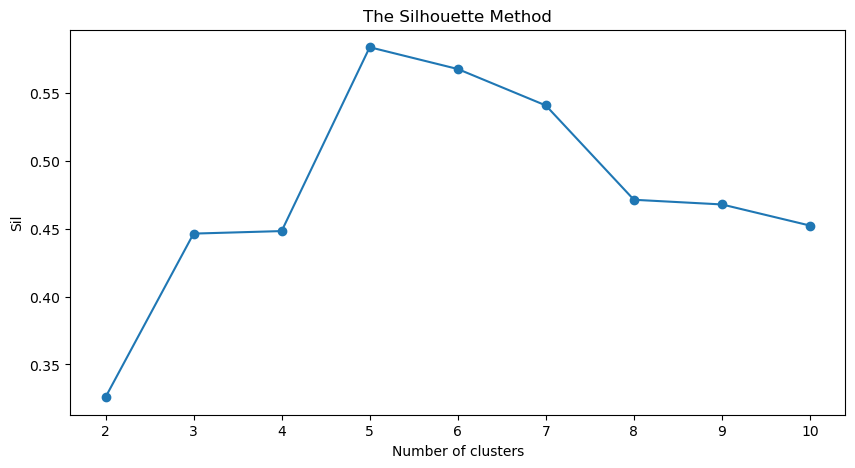

In [75]:
# Determine the number of clusters: Silhouette method.
# Find the range of clusters to be used using silhouette method
sil=[]
kmax=10

for k in range(2, kmax+1):
    kmeans_s = KMeans(n_clusters=k).fit(x)
    labels= kmeans_s.labels_
    sil.append(silhouette_score(x, labels, metric='euclidean'))

# Plot the silhouette method.
plt.plot(range(2, kmax+1), sil, marker='o')

# Insert the labels and title.
plt.title("The Silhouette Method")
plt.xlabel("Number of clusters")
plt.ylabel("Sil")
plt.savefig('silouehette_method.png',dpi=300)
plt.show()

#### Findings:
- Elbow method: curve started to flatten at k=5
- Silhouette method: peaks at 5
-> 5 might be the optimal of clusters for current data
-> Customers are divided into 5 different group segments based on annual income and customer score

## 4. Evaluate k-means model at different values of *k*

#### Five clusters

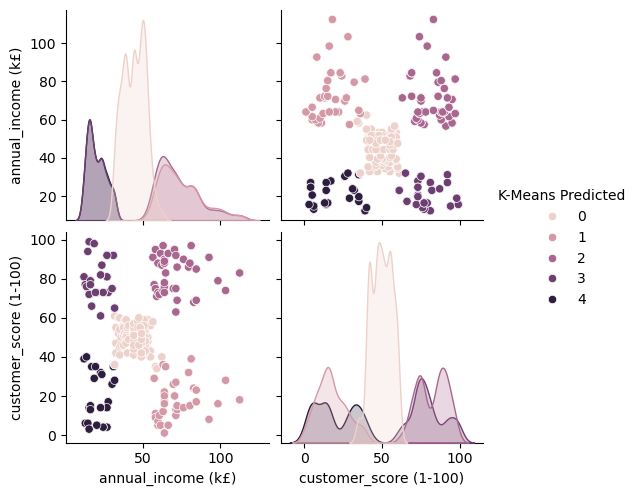

In [76]:
# Use five clusters as per 
kmeans = KMeans(n_clusters = 5, 
               max_iter=15000,
               init='k-means++', 
               random_state=0).fit(x)
clusters= kmeans.labels_
x['K-Means Predicted'] = clusters

# Plot the predicted.
sns.pairplot(x, hue='K-Means Predicted', diag_kind='kde')

In [77]:
# Check the number of observations per predicted class
x['K-Means Predicted'].value_counts()

K-Means Predicted
0    774
2    356
1    330
4    271
3    269
Name: count, dtype: int64

In [78]:
# View the K-Means predicted
print(x.head())

   annual_income (k£)  customer_score (1-100)  K-Means Predicted
0               12.30                      39                  4
1               12.30                      81                  3
2               13.12                       6                  4
3               13.12                      77                  3
4               13.94                      40                  4


<Axes: xlabel='annual_income (k£)', ylabel='customer_score (1-100)'>

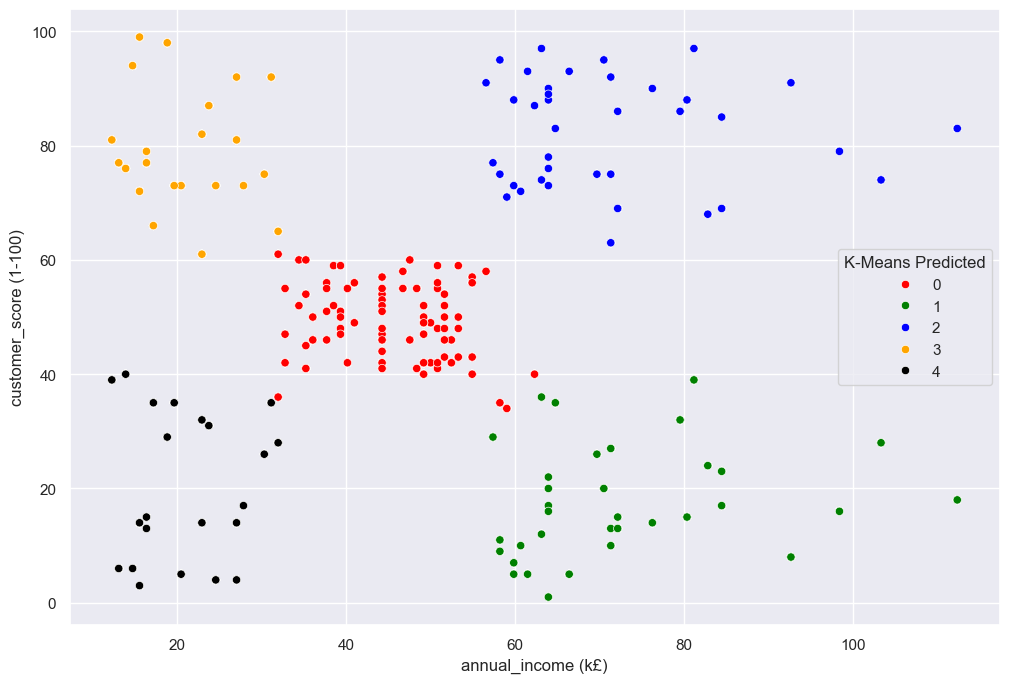

In [79]:
# Visualising the clusters.
# Set the plot size
sns.set(rc = {'figure.figsize':(12, 8)})

# Create a scatterplot
sns.scatterplot(x='annual_income (k£)', y='customer_score (1-100)', 
                data=x, 
                hue='K-Means Predicted',
                palette=['red', 'green', 'blue','orange', 'black'])

#### Four clusters

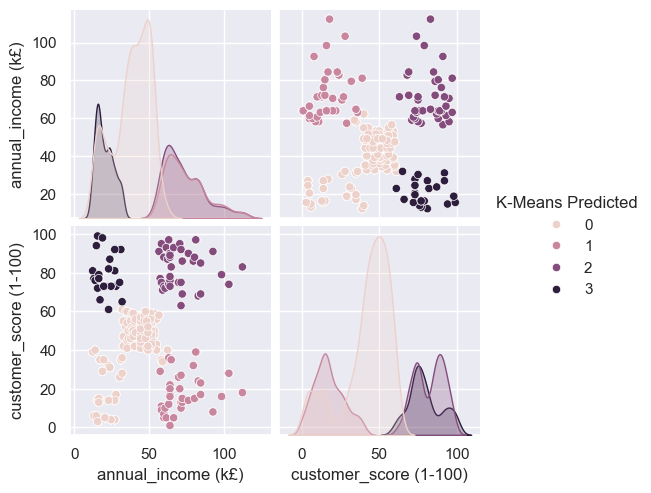

In [80]:
# Use five clusters as per 
x4= df3[['annual_income (k£)', 'customer_score (1-100)']]
kmeans_4 = KMeans(n_clusters = 4, 
               max_iter=15000,
               init='k-means++', 
               random_state=0).fit(x4)
clusters_4= kmeans_4.labels_
x4['K-Means Predicted'] = clusters_4

# Plot the predicted.
sns.pairplot(x4, hue='K-Means Predicted', diag_kind='kde')

In [81]:
# Check the number of observations per predicted class
x4['K-Means Predicted'].value_counts()

K-Means Predicted
0    1045
2     356
1     330
3     269
Name: count, dtype: int64

In [82]:
# View the K-Means predicted.
print(x4.head())

   annual_income (k£)  customer_score (1-100)  K-Means Predicted
0               12.30                      39                  0
1               12.30                      81                  3
2               13.12                       6                  0
3               13.12                      77                  3
4               13.94                      40                  0


<Axes: xlabel='annual_income (k£)', ylabel='customer_score (1-100)'>

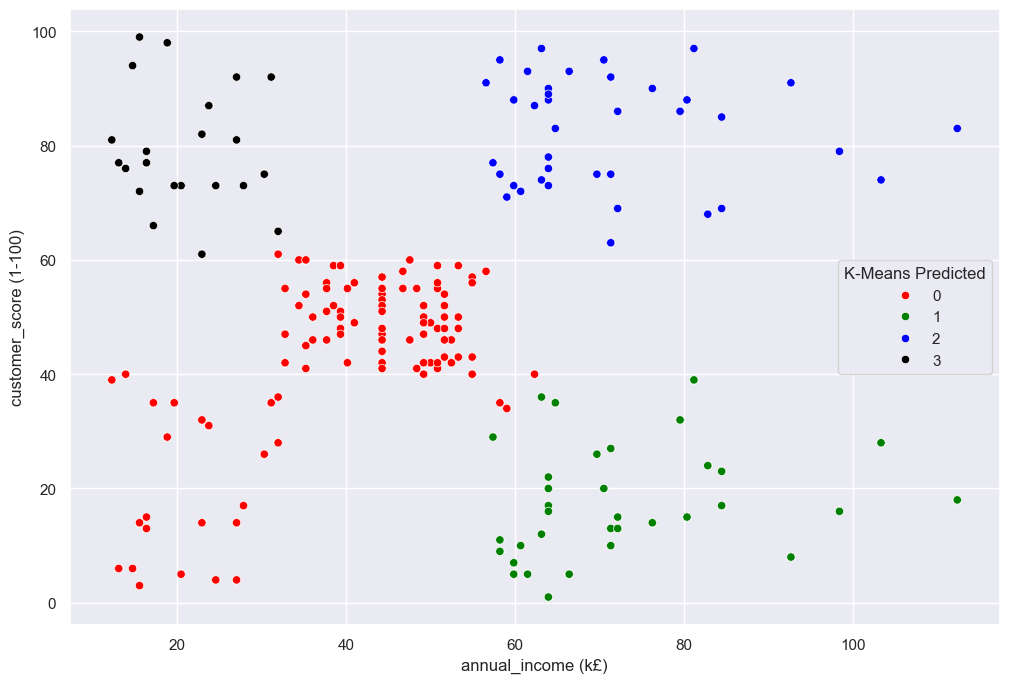

In [83]:
# Visualising the clusters.
# Set the plot size
sns.set(rc = {'figure.figsize':(12, 8)})

# Create a scatterplot
sns.scatterplot(x='annual_income (k£)', y='customer_score (1-100)', 
                data=x4, 
                hue='K-Means Predicted',
                palette=['red', 'green', 'blue', 'black'])

#### Decision about choosing which number of clusters to go:

The number of customers in groups 2, 1 and 3 is similar when using k=5 or k=4
When using k=5, the group 0 in k=4 were divided to group 0 and group 4. Creating 2 new distinct groups clearly defined the distinction between each customers groups.

-> Final decision: choosing k=5 -> divide customers into 5 groups

## 5. Fit the final model

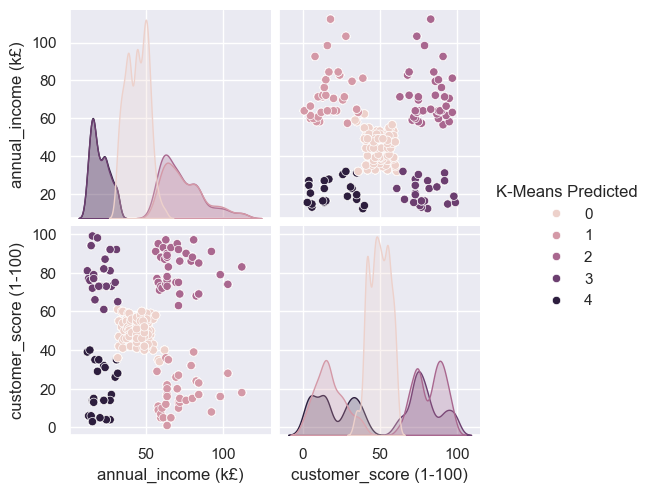

In [84]:
# Use five clusters as per 
kmeans = KMeans(n_clusters = 5, 
               max_iter=15000,
               init='k-means++', 
               random_state=0).fit(x)
clusters= kmeans.labels_
x['K-Means Predicted'] = clusters

# Plot the predicted.
sns.pairplot(x, hue='K-Means Predicted', diag_kind='kde')

In [85]:
# Check the number of observations per predicted class
x['K-Means Predicted'].value_counts()

K-Means Predicted
0    774
2    356
1    330
4    271
3    269
Name: count, dtype: int64

## 6. Plot and interpret the clusters

   annual_income (k£)  customer_score (1-100)  K-Means Predicted
0               12.30                      39                  4
1               12.30                      81                  3
2               13.12                       6                  4
3               13.12                      77                  3
4               13.94                      40                  4


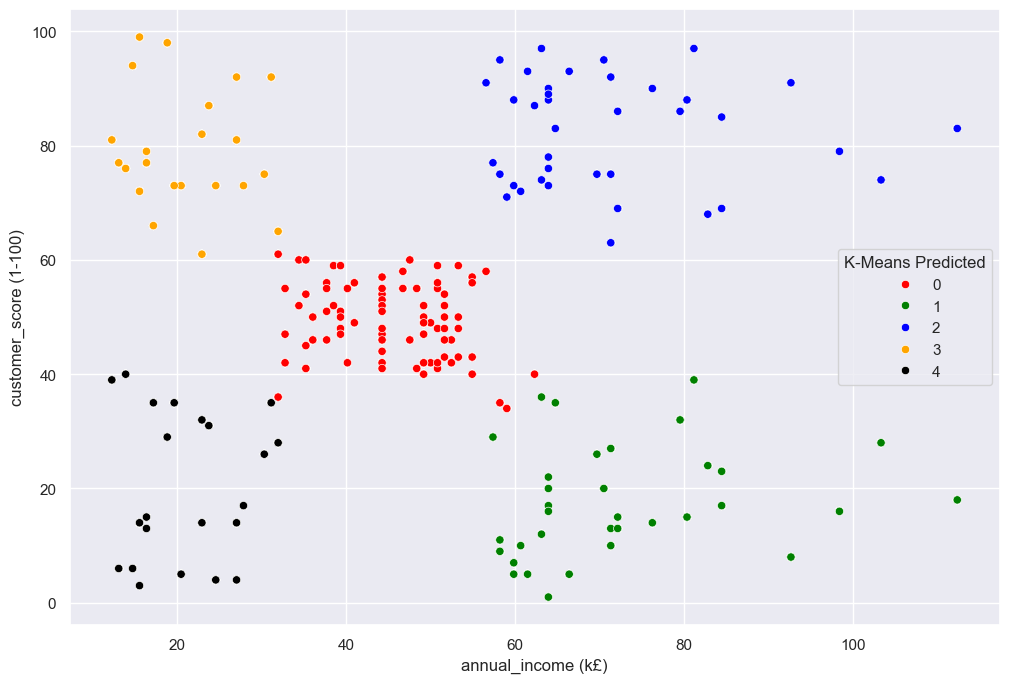

In [86]:
# Visualising the clusters.
# Set the plot size
sns.set(rc = {'figure.figsize':(12, 8)})

# Create a scatterplot
sns.scatterplot(x='annual_income (k£)', y='customer_score (1-100)', 
                data=x, 
                hue='K-Means Predicted',
                palette=['red', 'green', 'blue','orange', 'black'])

# View the K-Means predicted
plt.savefig('scatterplot_kmeans_5.png', dpi=300)
print(x.head())

## 7. Insights and observations

> By using k-means clusterings methods, I have managed to identify different customer groups with similar customer behaviour based on their annual income and customer score.
> In particular:
- Cluster 0 — Middle Income, Average Score (Red, n=774 — largest group)

Income: ~£40–65k, Score: ~40–60
The "average" customer — moderate spender, moderate engagement
- Cluster 2 — High Income, High Score (Blue, n=356)

Income: ~£55–100k+, Score: ~70–97

- Cluster 1 — High Income, Low Score (Green, n=330)
Income: ~£55–105k+, Score: ~1–40
Earn well but disengage — high potential, worth deep dive more

- Cluster 4 — Low Income, Low Score (Black, n=271)

Income: ~£10–35k, Score: ~3–40
Least engaged and lowest spending 

- Cluster 3 — Low Income, High Score (Orange, n=269)

Income: ~£10–35k, Score: ~65–99
Loyal despite low income — highly engaged, likely value-driven customers

# Part 4: Sentiment analysis of customer reviews (NLP)

## 1. Load and explore the data

In [87]:
# Import all the necessary packages.
import pandas as pd
import numpy as np
import nltk 
import os 
import matplotlib.pyplot as plt

# Import the required tokenisation model
nltk.download ('punkt')
nltk.download ('stopwords')

from wordcloud import WordCloud
from nltk.tokenize import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from textblob import TextBlob
from scipy.stats import norm

# Import Counter.
from collections import Counter

import warnings
warnings.filterwarnings('ignore')

In [88]:
# View DataFrame.
reviews_new

,gender,age,annual_income (k£),customer_score (1-100),loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,graduate,291,As my review of GF9's previous screens these w...,Money trap
...,...,...,...,...,...,...,...,...,...
1995,Female,37,84.46,69,4031,PhD,977,The perfect word game for mixed ages (with Mom...,The perfect word game for mixed ages (with Mom
1996,Female,43,92.66,8,539,PhD,979,Great game. Did not think I would like it whe...,Super fun
1997,Male,34,92.66,91,5614,graduate,1012,Great game for all.........\nKeeps the mind ni...,Great Game
1998,Male,34,98.40,16,1048,PhD,1031,fun game!,Four Stars


In [89]:
# Explore data set.
reviews_new.isnull().sum()

gender                    0
age                       0
annual_income (k£)        0
customer_score (1-100)    0
loyalty_points            0
education                 0
product                   0
review                    0
summary                   0
dtype: int64

In [90]:
# Keep necessary columns. Drop unnecessary columns.
survey = reviews_new[['review', 'summary']]

# View DataFrame.
survey

,review,summary
0,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,As my review of GF9's previous screens these w...,Money trap
...,...,...
1995,The perfect word game for mixed ages (with Mom...,The perfect word game for mixed ages (with Mom
1996,Great game. Did not think I would like it whe...,Super fun
1997,Great game for all.........\nKeeps the mind ni...,Great Game
1998,fun game!,Four Stars


In [91]:
# Determine if there are any missing values.
survey.isnull().sum()

review     0
summary    0
dtype: int64

## 2. Prepare the data for NLP
### 2a) Change to lower case and join the elements in each of the columns respectively (review and summary)

In [92]:
# Review: Change all to lower case and join with a space.
survey['review'] = survey['review'].apply(lambda x: " ".join(x.lower() for x in x.split()))

In [93]:
# Summary: Change all to lower case and join with a space.
survey['summary'] = survey['summary'].apply(lambda x: " ".join(x.lower() for x in x.split()))

In [94]:
# View the DataFrame after the change
survey

,review,summary
0,"when it comes to a dm's screen, the space on t...",the fact that 50% of this space is wasted on a...
1,an open letter to galeforce9*: your unpainted ...,another worthless dungeon master's screen from...
2,"nice art, nice printing. why two panels are fi...","pretty, but also pretty useless"
3,amazing buy! bought it as a gift for our new d...,five stars
4,as my review of gf9's previous screens these w...,money trap
...,...,...
1995,the perfect word game for mixed ages (with mom...,the perfect word game for mixed ages (with mom
1996,great game. did not think i would like it when...,super fun
1997,great game for all......... keeps the mind nim...,great game
1998,fun game!,four stars


### 2b) Replace punctuation in each of the columns respectively (review and summary)

In [95]:
# Replace all the punctuation in the review column.
survey['review'] = survey['review'].str.replace('[^\w\s]', '', regex=True)

# View output.
survey['review']

0       when it comes to a dms screen the space on the...
1       an open letter to galeforce9 your unpainted mi...
2       nice art nice printing why two panels are fill...
3       amazing buy bought it as a gift for our new dm...
4       as my review of gf9s previous screens these we...
                              ...                        
1995    the perfect word game for mixed ages with mom ...
1996    great game did not think i would like it when ...
1997             great game for all keeps the mind nimble
1998                                             fun game
1999    this game is fun a lot like scrabble without a...
Name: review, Length: 2000, dtype: object

In [96]:
# Replace all the punctuation in the summary column.
survey['summary'] = survey['summary'].str.replace('[^\w\s]', '', regex=True)

# View output.
survey['summary']

0       the fact that 50 of this space is wasted on ar...
1       another worthless dungeon masters screen from ...
2                          pretty but also pretty useless
3                                              five stars
4                                              money trap
                              ...                        
1995        the perfect word game for mixed ages with mom
1996                                            super fun
1997                                           great game
1998                                           four stars
1999                                       love this game
Name: summary, Length: 2000, dtype: object

### 2c) Drop duplicates in both columns

In [97]:
# Drop duplicates in both columns.
survey = survey.drop_duplicates(subset=['review', 'summary'])
# View DataFrame.
survey

,review,summary
0,when it comes to a dms screen the space on the...,the fact that 50 of this space is wasted on ar...
1,an open letter to galeforce9 your unpainted mi...,another worthless dungeon masters screen from ...
2,nice art nice printing why two panels are fill...,pretty but also pretty useless
3,amazing buy bought it as a gift for our new dm...,five stars
4,as my review of gf9s previous screens these we...,money trap
...,...,...
1995,the perfect word game for mixed ages with mom ...,the perfect word game for mixed ages with mom
1996,great game did not think i would like it when ...,super fun
1997,great game for all keeps the mind nimble,great game
1998,fun game,four stars


## 3. Tokenise and create wordclouds

In [98]:
# Create new DataFrame (copy DataFrame).

survey1 = survey
# View DataFrame.
survey1

,review,summary
0,when it comes to a dms screen the space on the...,the fact that 50 of this space is wasted on ar...
1,an open letter to galeforce9 your unpainted mi...,another worthless dungeon masters screen from ...
2,nice art nice printing why two panels are fill...,pretty but also pretty useless
3,amazing buy bought it as a gift for our new dm...,five stars
4,as my review of gf9s previous screens these we...,money trap
...,...,...
1995,the perfect word game for mixed ages with mom ...,the perfect word game for mixed ages with mom
1996,great game did not think i would like it when ...,super fun
1997,great game for all keeps the mind nimble,great game
1998,fun game,four stars


In [99]:
# Install the required tokenisation function.
from nltk.tokenize import sent_tokenize
from nltk.tokenize import word_tokenize

In [100]:
# Apply tokenisation to both columns.
survey1['review'] = survey1['review'].apply(word_tokenize)
survey1['summary']= survey1['summary'].apply(word_tokenize)

# View DataFrame.
survey1.reset_index(inplace=True)
survey1

,index,review,summary
0,0,"[when, it, comes, to, a, dms, screen, the, spa...","[the, fact, that, 50, of, this, space, is, was..."
1,1,"[an, open, letter, to, galeforce9, your, unpai...","[another, worthless, dungeon, masters, screen,..."
2,2,"[nice, art, nice, printing, why, two, panels, ...","[pretty, but, also, pretty, useless]"
3,3,"[amazing, buy, bought, it, as, a, gift, for, o...","[five, stars]"
4,4,"[as, my, review, of, gf9s, previous, screens, ...","[money, trap]"
...,...,...,...
1956,1995,"[the, perfect, word, game, for, mixed, ages, w...","[the, perfect, word, game, for, mixed, ages, w..."
1957,1996,"[great, game, did, not, think, i, would, like,...","[super, fun]"
1958,1997,"[great, game, for, all, keeps, the, mind, nimble]","[great, game]"
1959,1998,"[fun, game]","[four, stars]"


### Analyse review column

In [101]:
# Define an empty list of tokens.
all_tokens_review = []

for i in range(survey1.shape[0]):
    # Add each token to the list.
    all_tokens_review = all_tokens_review + survey1['review'][i]

In [102]:
# Import the FreqDist class.

from nltk.probability import FreqDist

# Calculate the frequency distribution

fdist_review = FreqDist(all_tokens_review)

# Preview the data
fdist_review

FreqDist({'the': 5451, 'and': 3233, 'to': 3162, 'a': 3160, 'of': 2488, 'i': 2090, 'it': 2083, 'is': 1782, 'this': 1776, 'game': 1671, ...})

In [103]:
# Filter out tokens that are neither alphabets nor numbers (to eliminate punctuation marks, etc.).
tokens_review = [word for word in all_tokens_review if word.isalnum()]

#### Eliminate stopwords in review column

In [104]:
# Download the stopword list.
nltk.download ('stopwords')
from nltk.corpus import stopwords

# Create a set of English stopwords.
english_stopwords = set(stopwords.words('english'))

# Create a filtered list of tokens without stopwords.
tokens_review_2 = [x for x in tokens_review if x.lower() not in english_stopwords]

# Define an empty string variable.
tokens2_string_review = ''

for value in tokens_review_2:
    # Add each filtered token word to the string.
    tokens2_string_review = tokens2_string_review + value + ' '

#### Create a word cloud

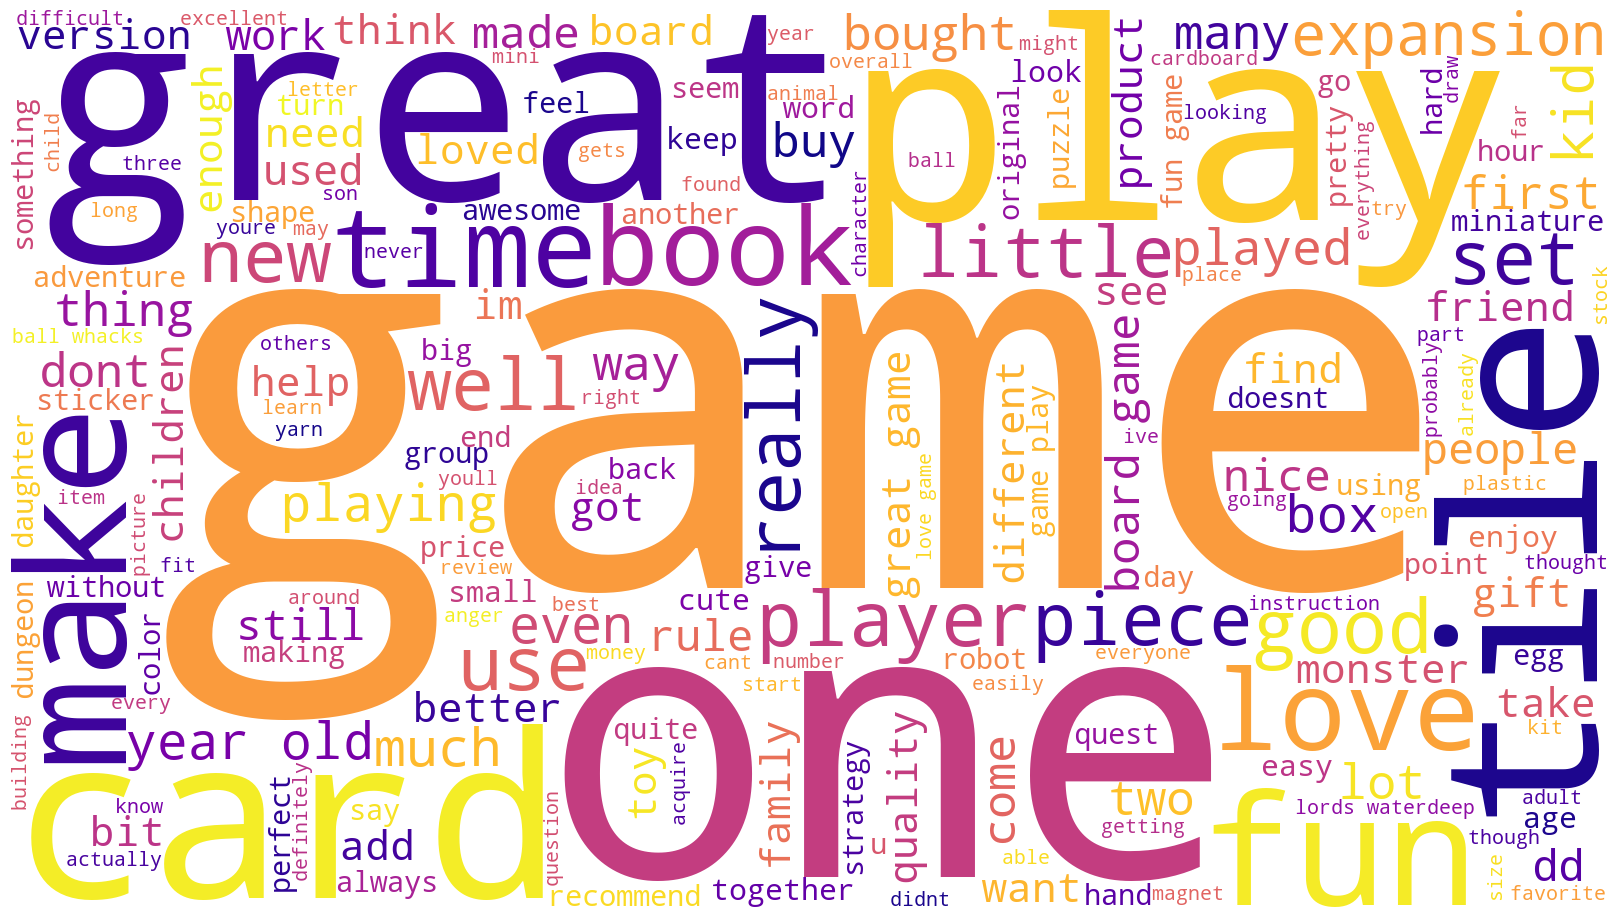

In [105]:
wordcloud = WordCloud(width = 1600, height = 900, 
                background_color ='white', 
                colormap='plasma', 
                min_font_size = 10).generate(tokens2_string_review) 

# Plot the WordCloud image.                        
plt.figure(figsize = (16, 9), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis('off') 
plt.tight_layout(pad = 0) 
plt.savefig('wordcloud_review.png', dpi=300)
plt.show()

### Analyse Summary column

In [106]:
# Define an empty list of tokens.
all_tokens_summary = []

for i in range(survey1.shape[0]):
    # Add each token to the list.
    all_tokens_summary = all_tokens_summary + survey1['summary'][i]

In [107]:
# Import the FreqDist class.

from nltk.probability import FreqDist

# Calculate the frequency distribution

fdist_summary = FreqDist(all_tokens_summary)

# Preview the data
fdist_summary

FreqDist({'stars': 427, 'five': 342, 'game': 319, 'great': 295, 'the': 261, 'a': 240, 'for': 232, 'fun': 218, 'to': 192, 'and': 168, ...})

In [108]:
# Filter out tokens that are neither alphabets nor numbers (to eliminate punctuation marks, etc.).
summary_review = [word for word in all_tokens_summary if word.isalnum()]

#### Eliminate stopwords in the summary column

In [109]:
# Download the stopword list.
nltk.download ('stopwords')
from nltk.corpus import stopwords

# Create a set of English stopwords.
english_stopwords = set(stopwords.words('english'))

# Create a filtered list of tokens without stopwords.
summary_review_2 = [x for x in summary_review if x.lower() not in english_stopwords]

# Define an empty string variable.
tokens2_string_summary = ''

for value in summary_review_2:
    # Add each filtered token word to the string.
    tokens2_string_summary = tokens2_string_summary + value + ' '

#### Create a word cloud

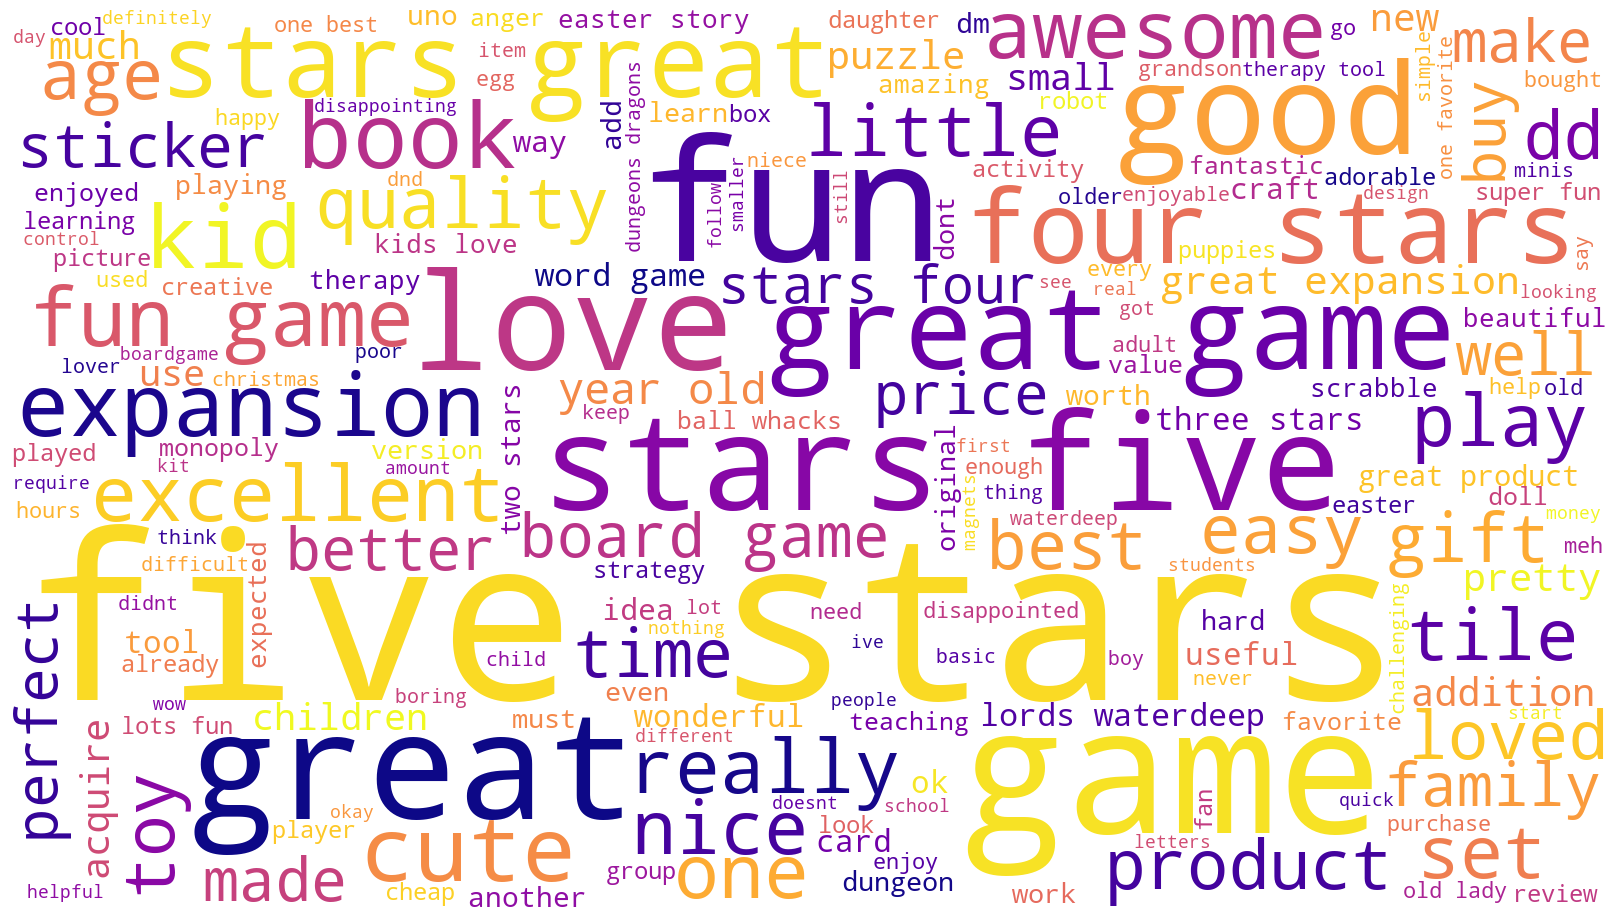

In [110]:
wordcloud = WordCloud(width = 1600, height = 900, 
                background_color ='white', 
                colormap='plasma', 
                min_font_size = 10).generate(tokens2_string_summary) 

# Plot the WordCloud image.                        
plt.figure(figsize = (16, 9), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis('off') 
plt.tight_layout(pad = 0) 
plt.savefig('wordcloud_summary.png', dpi=300)
plt.show()

## 4. Frequency distribution and polarity
### 4a) Create frequency distribution for both columns

In [111]:
# Determine the frequency distribution.
# Define an empty list of tokens.
all_tokens_final = []

for i in range(survey1.shape[0]):
    # Add each token to the list.
    all_tokens_final  = all_tokens_summary + all_tokens_review

print(all_tokens_final)

['the', 'fact', 'that', '50', 'of', 'this', 'space', 'is', 'wasted', 'on', 'art', 'and', 'not', 'terribly', 'informative', 'or', 'needed', 'art', 'another', 'worthless', 'dungeon', 'masters', 'screen', 'from', 'galeforce9', 'pretty', 'but', 'also', 'pretty', 'useless', 'five', 'stars', 'money', 'trap', 'five', 'stars', 'best', 'gm', 'screen', 'ever', 'five', 'stars', 'great', 'but', 'could', 'be', 'even', 'better', 'another', 'missed', 'opportunity', 'not', 'a', 'value', 'add', 'to', 'the', 'product', 'line', 'five', 'stars', 'love', 'the', 'map', 'not', 'a', 'general', 'dm', 'screen', 'very', 'weak', 'game', 'fell', 'completely', 'flat', 'five', 'stars', 'good', 'book', 'buckley', 'was', 'a', 'card', 'mommer', 'very', 'advanced', 'but', 'as', 'good', 'as', 'it', 'gets', 'you', 'better', 'know', 'what', 'youre', 'getting', 'into', 'dont', 'bother', 'the', 'worst', 'value', 'ive', 'ever', 'seen', 'not', 'enough', 'product', 'good', 'product', 'but', 'temporary', 'tattoos', 'were', 'good

In [112]:
# Import the FreqDist class.

from nltk.probability import FreqDist

# Calculate the frequency distribution

fdist_final = FreqDist(all_tokens_final)

# Preview the data
fdist_final

FreqDist({'the': 5712, 'and': 3401, 'a': 3400, 'to': 3354, 'of': 2627, 'it': 2233, 'i': 2176, 'game': 1990, 'this': 1911, 'is': 1885, ...})

### 4b) Remove alphanumeric characters and stopwords

In [113]:
# Filter out tokens that are neither alphabets nor numbers (to eliminate punctuation marks, etc.).
tokens_final = [word for word in all_tokens_final if word.isalnum()]

In [114]:
# Remove all the stopwords

nltk.download ('stopwords')
from nltk.corpus import stopwords

# Create a set of English stopwords.
english_stopwords = set(stopwords.words('english'))

# Create a filtered list of tokens without stopwords.
tokens_final_2 = [x for x in tokens_final if x.lower() not in english_stopwords]

# Define an empty string variable.
tokens2_final = ''

for value in tokens_final_2:
    # Add each filtered token word to the string.
    tokens2_final = tokens2_final + value + ' '

### 4c) Create wordcloud without stopwords

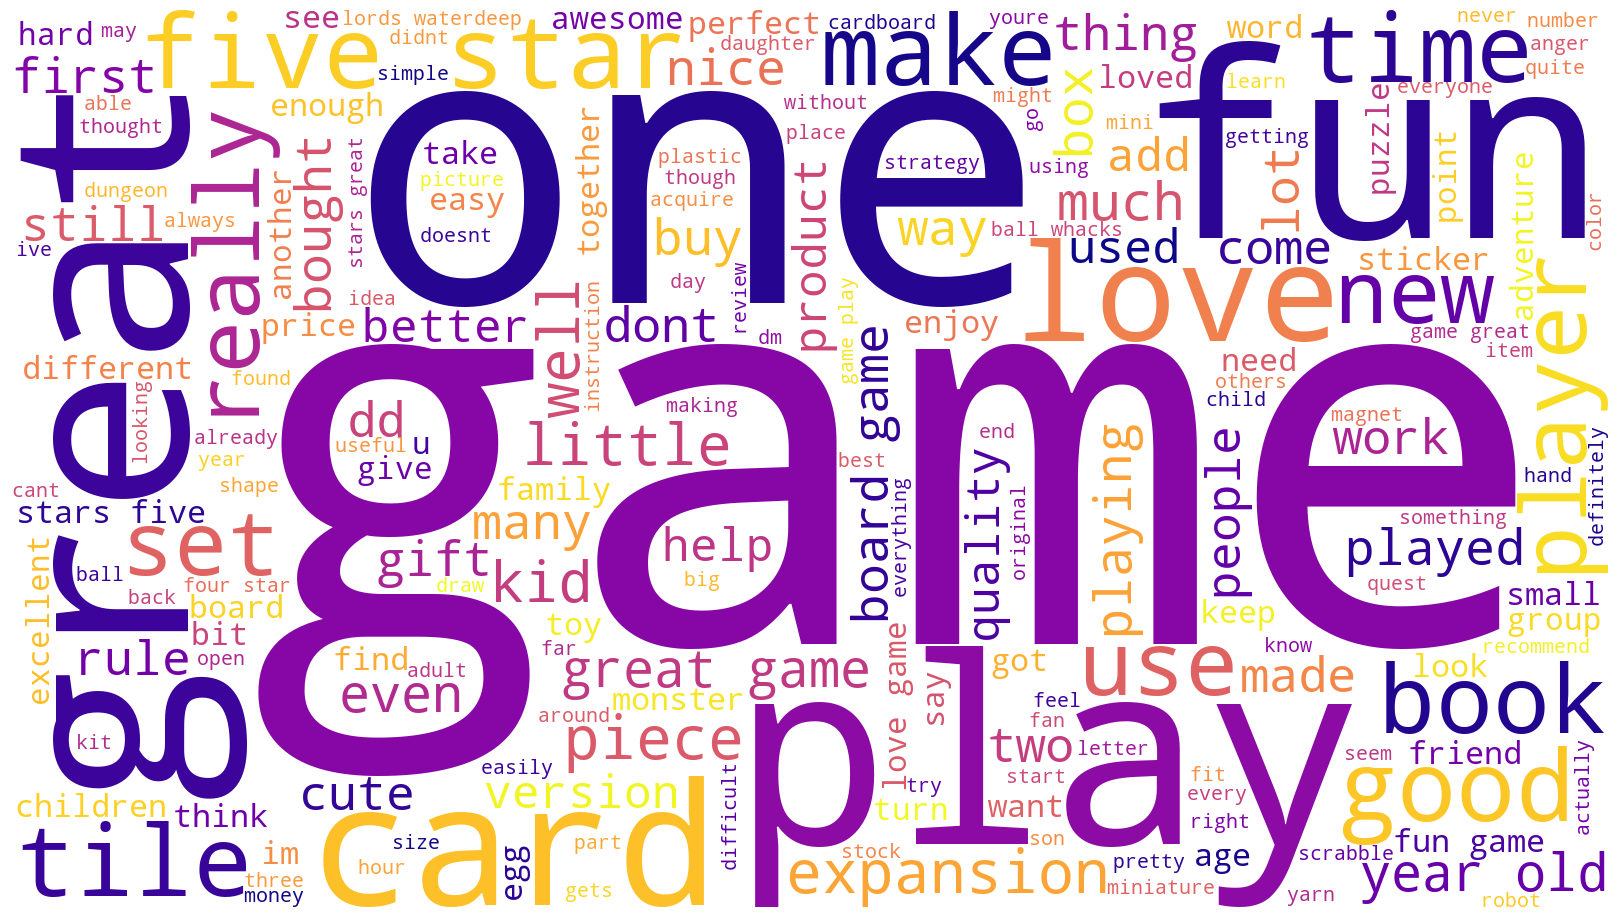

In [115]:
# Create a wordcloud without stop words.
wordcloud = WordCloud(width = 1600, height = 900, 
                background_color ='white', 
                colormap='plasma', 
                min_font_size = 10).generate(tokens2_final) 

# Plot the WordCloud image.                        
plt.figure(figsize = (16, 9), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis('off') 
plt.tight_layout(pad = 0) 
plt.savefig('wordcloud_combined_summary_review.png', dpi=300)
plt.show()

### 4d) Identify 15 most common words and polarity

In [116]:
# Determine the 15 most common words in review column
fdist_review = FreqDist(tokens_review_2)
fdist_review

FreqDist({'game': 1671, 'great': 580, 'fun': 552, 'one': 530, 'play': 502, 'like': 414, 'love': 323, 'really': 319, 'get': 319, 'cards': 301, ...})

In [117]:
# Import the Counter class.
from collections import Counter

# Generate a DataFrame from Counter.
counts_review = pd.DataFrame(Counter(tokens_review_2).most_common(15),
                      columns=['Word', 'Frequency']).set_index('Word')

# Preview data.
counts_review

,Frequency
Word,
game,1671
great,580
fun,552
one,530
play,502
like,414
love,323
really,319
get,319


In [118]:
# Determine the 15 most common words in the summary column
fdist_summary = FreqDist(summary_review_2)
fdist_summary

FreqDist({'stars': 427, 'five': 342, 'game': 319, 'great': 295, 'fun': 218, 'love': 93, 'good': 92, 'four': 58, 'like': 54, 'expansion': 52, ...})

In [119]:
# Import the Counter class.
from collections import Counter

# Generate a DataFrame from Counter.
counts_summary = pd.DataFrame(Counter(summary_review_2).most_common(15),
                      columns=['Word', 'Frequency']).set_index('Word')

# Preview data.
counts_summary

,Frequency
Word,
stars,427
five,342
game,319
great,295
fun,218
love,93
good,92
four,58
like,54


In [120]:
# Determine the 15 most common words in both columns
fdist_final = FreqDist(tokens_final_2)
fdist_final

FreqDist({'game': 1990, 'great': 875, 'fun': 770, 'one': 568, 'play': 528, 'like': 468, 'stars': 464, 'love': 416, 'good': 381, 'five': 362, ...})

In [121]:
# Import the Counter class.
from collections import Counter

# Generate a DataFrame from Counter.
counts_final = pd.DataFrame(Counter(tokens_final_2).most_common(15),
                      columns=['Word', 'Frequency']).set_index('Word')

# Preview data.
counts_final

,Frequency
Word,
game,1990
great,875
fun,770
one,568
play,528
like,468
stars,464
love,416
good,381


## 5. Review Sentiment Polarity and Subjectivity: Plot histograms of polarity sentiment/ subjectivity (use 15 bins) and sentiment scores/subjectivity scores for the respective columns.

#### Determine Sentiment Polarity columns

In [122]:
# Install TextBlob.
%pip install textblob

# Import the necessary package.
from textblob import TextBlob

In [123]:
def generate_polarity(comment):
    '''Extract polarity score (-1 to +1) for each comment'''
    return TextBlob(comment).sentiment[0]

In [124]:
# Determine a new DataFrame
survey2 = survey1.copy()

# Rejoin tokens back into strings for both columns
survey2['review'] = survey2['review'].apply(lambda x: ' '.join(x))
survey2['summary'] = survey2['summary'].apply(lambda x: ' '.join(x))

# View the DataFrame
survey2

,index,review,summary
0,0,when it comes to a dms screen the space on the...,the fact that 50 of this space is wasted on ar...
1,1,an open letter to galeforce9 your unpainted mi...,another worthless dungeon masters screen from ...
2,2,nice art nice printing why two panels are fill...,pretty but also pretty useless
3,3,amazing buy bought it as a gift for our new dm...,five stars
4,4,as my review of gf9s previous screens these we...,money trap
...,...,...,...
1956,1995,the perfect word game for mixed ages with mom ...,the perfect word game for mixed ages with mom
1957,1996,great game did not think i would like it when ...,super fun
1958,1997,great game for all keeps the mind nimble,great game
1959,1998,fun game,four stars


In [125]:
# Determine sentiment polarity of both columns. 
survey2['review_polarity'] = survey2['review'].apply(generate_polarity)
survey2['summary_polarity']= survey2['summary'].apply(generate_polarity)
survey2['combined_polarity'] = (survey2['review_polarity'] + survey2['summary_polarity'])/2
# View output.
survey2

,index,review,summary,review_polarity,summary_polarity,combined_polarity
0,0,when it comes to a dms screen the space on the...,the fact that 50 of this space is wasted on ar...,-0.036111,0.150000,0.056944
1,1,an open letter to galeforce9 your unpainted mi...,another worthless dungeon masters screen from ...,0.035952,-0.800000,-0.382024
2,2,nice art nice printing why two panels are fill...,pretty but also pretty useless,0.116640,0.000000,0.058320
3,3,amazing buy bought it as a gift for our new dm...,five stars,0.578788,0.000000,0.289394
4,4,as my review of gf9s previous screens these we...,money trap,-0.316667,0.000000,-0.158333
...,...,...,...,...,...,...
1956,1995,the perfect word game for mixed ages with mom ...,the perfect word game for mixed ages with mom,0.168750,0.200000,0.184375
1957,1996,great game did not think i would like it when ...,super fun,0.158333,0.316667,0.237500
1958,1997,great game for all keeps the mind nimble,great game,0.200000,0.200000,0.200000
1959,1998,fun game,four stars,-0.050000,0.000000,-0.025000


#### Determine Subjectivity columns

In [126]:
# Define a function to extract a subjectivity score for the comment.
def generate_subjectivity(comment):
    return TextBlob(comment).sentiment[1]

In [127]:
# Determine subjectivity of both columns.  
survey2['review_subjectivity'] = survey2['review'].apply(generate_subjectivity)
survey2['summary_subjectivity']= survey2['summary'].apply(generate_subjectivity)
survey2['combined_subjectivity'] = (survey2['review_subjectivity'] + survey2['summary_subjectivity'])/2
# View output.
survey2

,index,review,summary,review_polarity,summary_polarity,combined_polarity,review_subjectivity,summary_subjectivity,combined_subjectivity
0,0,when it comes to a dms screen the space on the...,the fact that 50 of this space is wasted on ar...,-0.036111,0.150000,0.056944,0.486111,0.500000,0.493056
1,1,an open letter to galeforce9 your unpainted mi...,another worthless dungeon masters screen from ...,0.035952,-0.800000,-0.382024,0.442976,0.900000,0.671488
2,2,nice art nice printing why two panels are fill...,pretty but also pretty useless,0.116640,0.000000,0.058320,0.430435,0.733333,0.581884
3,3,amazing buy bought it as a gift for our new dm...,five stars,0.578788,0.000000,0.289394,0.784848,0.000000,0.392424
4,4,as my review of gf9s previous screens these we...,money trap,-0.316667,0.000000,-0.158333,0.316667,0.000000,0.158333
...,...,...,...,...,...,...,...,...,...
1956,1995,the perfect word game for mixed ages with mom ...,the perfect word game for mixed ages with mom,0.168750,0.200000,0.184375,0.491667,0.550000,0.520833
1957,1996,great game did not think i would like it when ...,super fun,0.158333,0.316667,0.237500,0.310043,0.433333,0.371688
1958,1997,great game for all keeps the mind nimble,great game,0.200000,0.200000,0.200000,0.575000,0.575000,0.575000
1959,1998,fun game,four stars,-0.050000,0.000000,-0.025000,0.300000,0.000000,0.150000


#### Visualisations with Review columns

> Using only Review Polarity Column

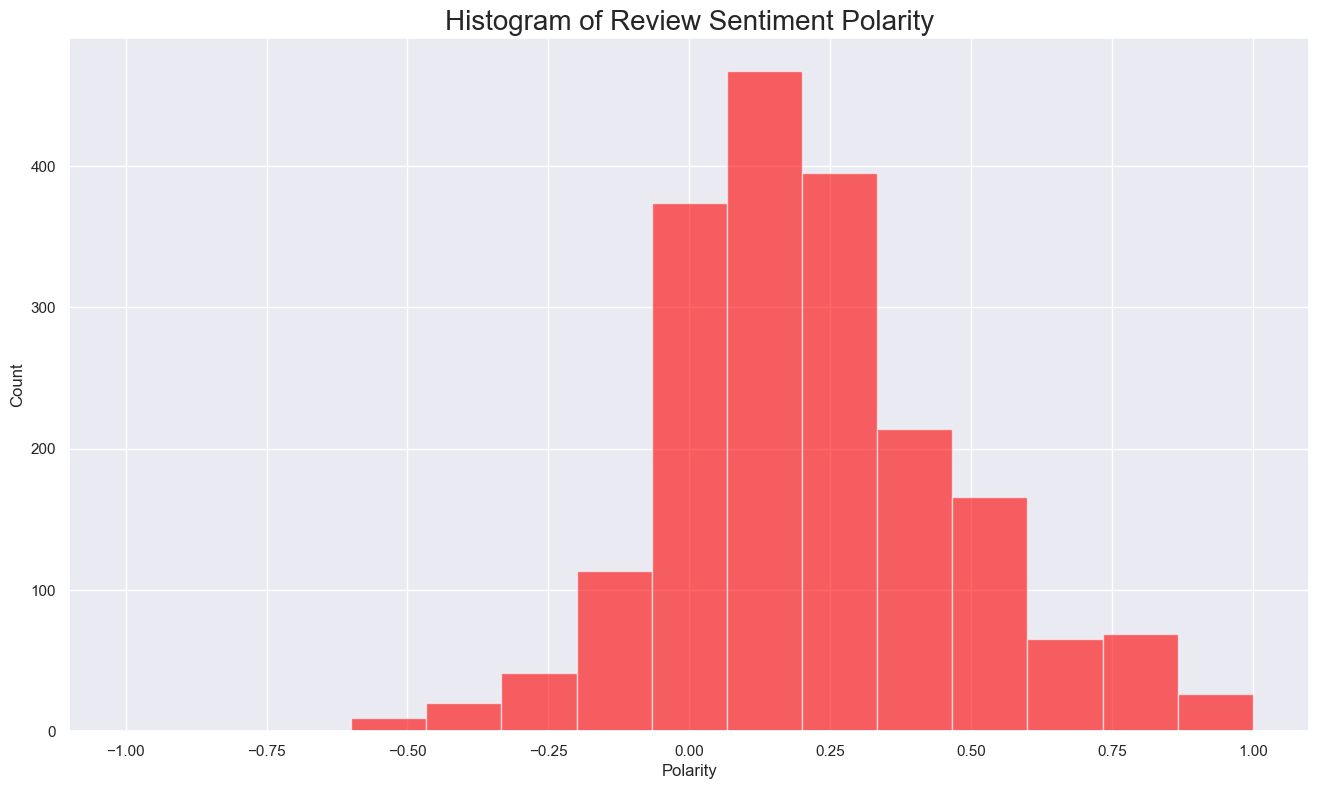

In [128]:
# Review: Create a histogram plot with bins = 15.
# Histogram of Sentiment Polarity
# Set the number of bins.
num_bins = 15

# Set the plot area.
plt.figure(figsize=(16,9))

# Define the bars.
n, bins, patches = plt.hist(survey2['review_polarity'], num_bins, facecolor='red', alpha=0.6)

# Set the labels.
plt.xlabel('Polarity', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.title('Histogram of Review Sentiment Polarity', fontsize=20)

plt.show()

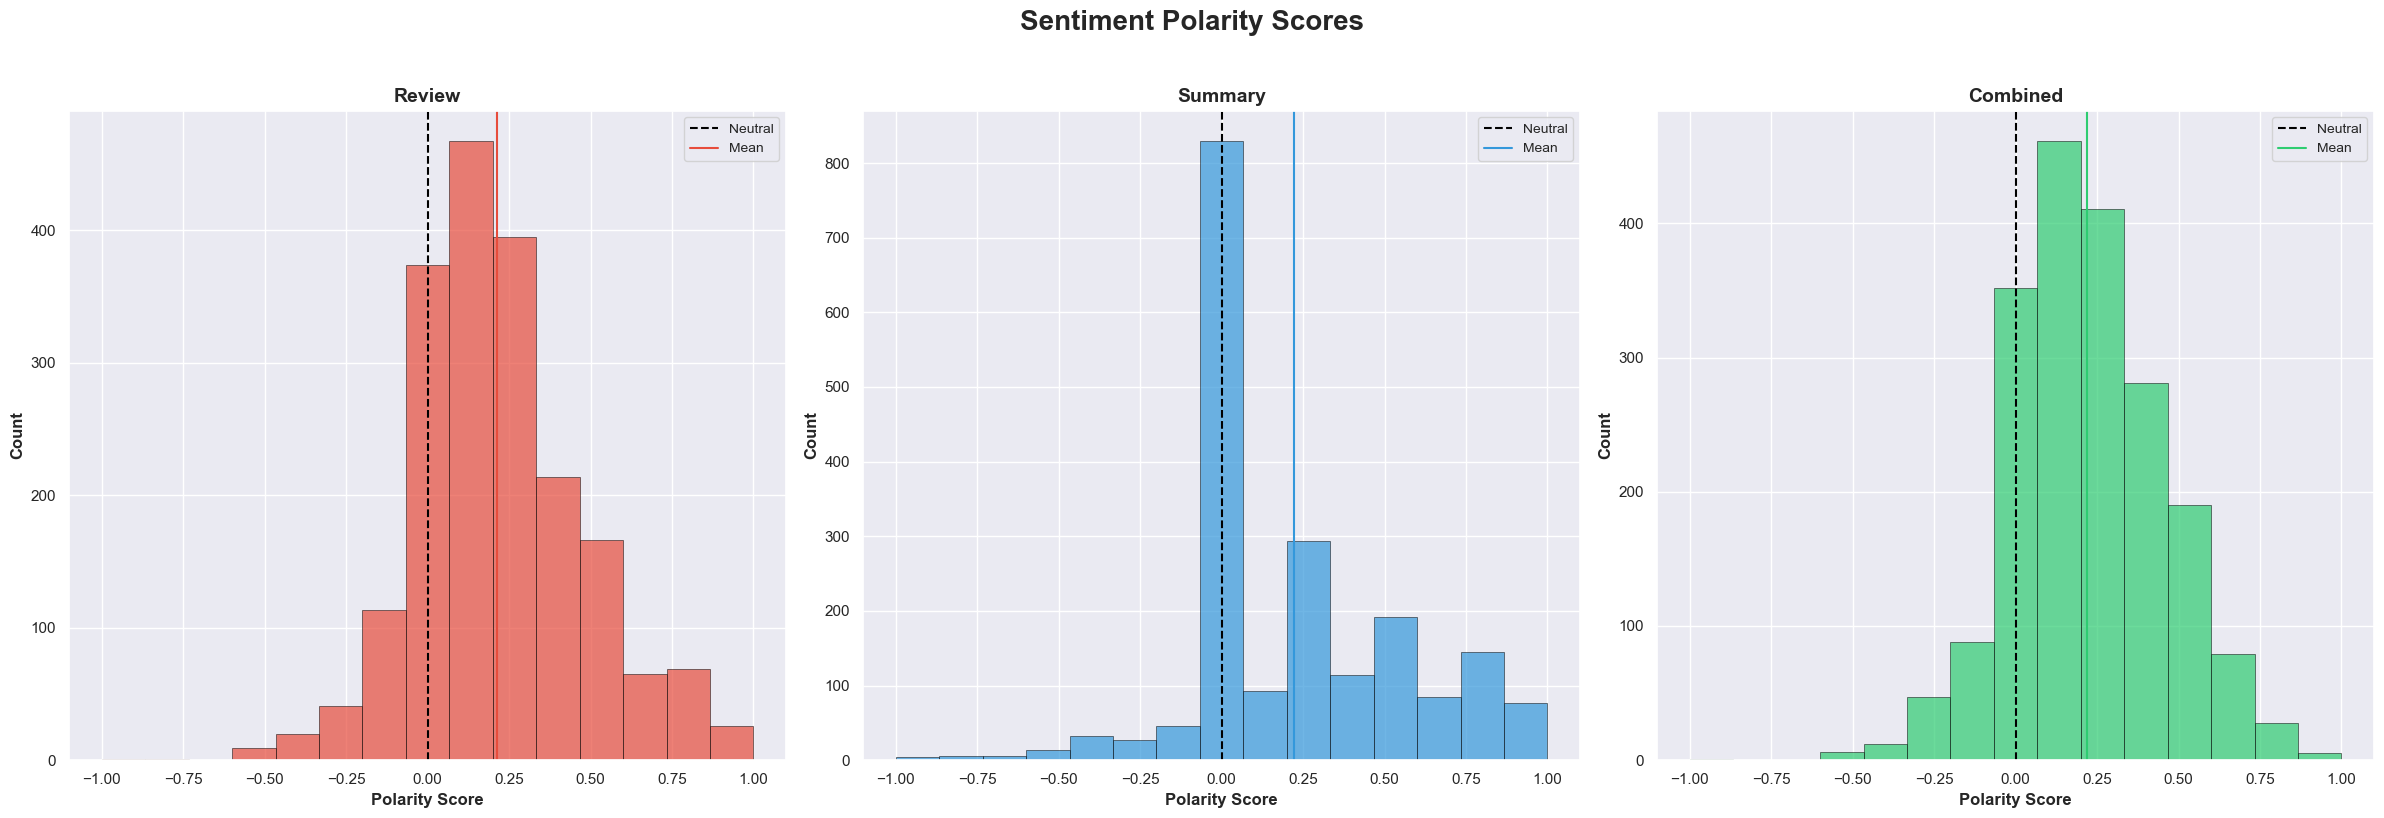

In [129]:
fig, axes = plt.subplots(1, 3, figsize=(24, 8))

# Review Polarity
axes[0].hist(survey2['review_polarity'], bins=15, facecolor='#E74C3C', alpha=0.7, edgecolor='black', linewidth=0.5)
axes[0].set_title('Review', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Polarity Score', fontsize=12,fontweight='bold')
axes[0].set_ylabel('Count', fontsize=12, fontweight='bold')
axes[0].axvline(x=0, color='black', linestyle='--', linewidth=1.5, label='Neutral')
axes[0].axvline(survey2['review_polarity'].mean(), color='#E74C3C', linestyle='-', linewidth=1.5, label='Mean')
axes[0].legend(fontsize=10)

# Summary Polarity
axes[1].hist(survey2['summary_polarity'], bins=15, facecolor='#3498DB', alpha=0.7, edgecolor='black', linewidth=0.5)
axes[1].set_title('Summary', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Polarity Score', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Count', fontsize=12, fontweight='bold')
axes[1].axvline(x=0, color='black', linestyle='--', linewidth=1.5, label='Neutral')
axes[1].axvline(survey2['summary_polarity'].mean(), color='#3498DB', linestyle='-', linewidth=1.5, label='Mean')
axes[1].legend(fontsize=10)

# Combined Polarity
axes[2].hist(survey2['combined_polarity'], bins=15, facecolor='#2ECC71', alpha=0.7, edgecolor='black', linewidth=0.5)
axes[2].set_title('Combined', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Polarity Score', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Count', fontsize=12,fontweight='bold' )
axes[2].axvline(x=0, color='black', linestyle='--', linewidth=1.5, label='Neutral')
axes[2].axvline(survey2['combined_polarity'].mean(), color='#2ECC71', linestyle='-', linewidth=1.5, label='Mean')
axes[2].legend(fontsize=10)

plt.suptitle('Sentiment Polarity Scores', fontsize=20, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('sentiment_polarity_scores.png', dpi=300)
plt.show()

#### Visualisation with subjectivity columns

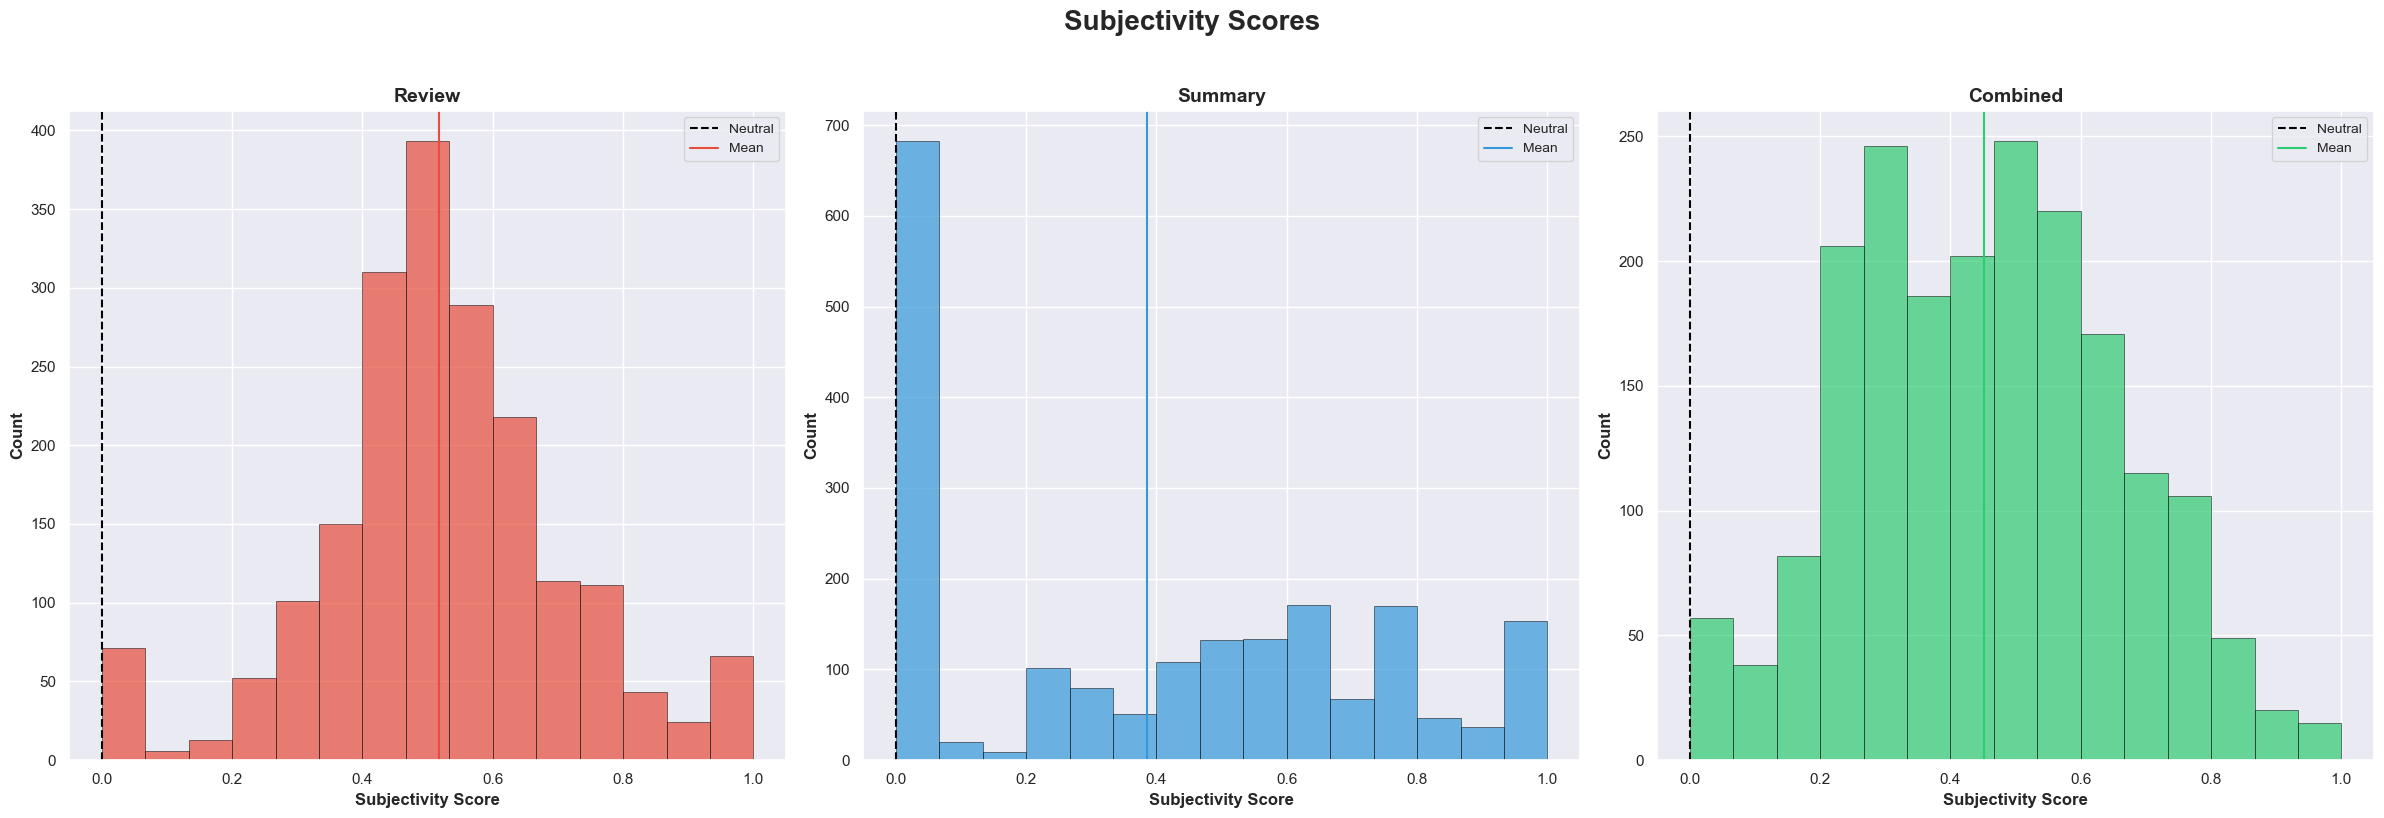

In [130]:
fig, axes = plt.subplots(1, 3, figsize=(24, 8))

# Review Polarity
axes[0].hist(survey2['review_subjectivity'], bins=15, facecolor='#E74C3C', alpha=0.7, edgecolor='black', linewidth=0.5)
axes[0].set_title('Review', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Subjectivity Score', fontsize=12,fontweight='bold')
axes[0].set_ylabel('Count', fontsize=12, fontweight='bold')
axes[0].axvline(x=0, color='black', linestyle='--', linewidth=1.5, label='Neutral')
axes[0].axvline(survey2['review_subjectivity'].mean(), color='#E74C3C', linestyle='-', linewidth=1.5, label='Mean')
axes[0].legend(fontsize=10)

# Summary Polarity
axes[1].hist(survey2['summary_subjectivity'], bins=15, facecolor='#3498DB', alpha=0.7, edgecolor='black', linewidth=0.5)
axes[1].set_title('Summary', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Subjectivity Score', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Count', fontsize=12, fontweight='bold')
axes[1].axvline(x=0, color='black', linestyle='--', linewidth=1.5, label='Neutral')
axes[1].axvline(survey2['summary_subjectivity'].mean(), color='#3498DB', linestyle='-', linewidth=1.5, label='Mean')
axes[1].legend(fontsize=10)

# Combined Polarity
axes[2].hist(survey2['combined_subjectivity'], bins=15, facecolor='#2ECC71', alpha=0.7, edgecolor='black', linewidth=0.5)
axes[2].set_title('Combined', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Subjectivity Score', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Count', fontsize=12,fontweight='bold' )
axes[2].axvline(x=0, color='black', linestyle='--', linewidth=1.5, label='Neutral')
axes[2].axvline(survey2['combined_subjectivity'].mean(), color='#2ECC71', linestyle='-', linewidth=1.5, label='Mean')
axes[2].legend(fontsize=10)

plt.suptitle('Subjectivity Scores', fontsize=20, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('subjectivity_scores.png', dpi=300)
plt.show()

## 6. Identify top 20 positive and negative reviews and summaries respectively

In [131]:
survey2.columns.tolist()

['index',
 'review',
 'summary',
 'review_polarity',
 'summary_polarity',
 'combined_polarity',
 'review_subjectivity',
 'summary_subjectivity',
 'combined_subjectivity']

#### Review columns

In [140]:
# Top 20 negative reviews.

negative_sentiment_review = survey2.nsmallest(20, 'review_polarity')

# Eliminate unnecessary columns.
negative_sentiment_review = negative_sentiment_review[['review',
 'review_polarity',
 'review_subjectivity']]

# Adjust the column width.
negative_sentiment_review.style.set_properties(subset=['review'], **{'width': '1200px'})

,review,review_polarity,review_subjectivity
207,booo unles you are patient know how to measure i didnt have the patience neither did my daughter boring unless you are a craft person which i am not,-1.000000,1.000000
181,incomplete kit very disappointing,-0.780000,0.910000
1773,im sorry i just find this product to be boring and to be frank juvenile,-0.583333,0.750000
362,one of my staff will be using this game soon so i dont know how well it works as yet but after looking at the cards i believe it will be helpful in getting a conversation started regarding anger and what to do to control it,-0.550000,0.300000
116,i bought this as a christmas gift for my grandson its a sticker book so how can i go wrong with this gift,-0.500000,0.900000
226,this was a gift for my daughter i found it difficult to use,-0.500000,1.000000
229,i found the directions difficult,-0.500000,1.000000
289,instructions are complicated to follow,-0.500000,1.000000
300,difficult,-0.500000,1.000000
1501,expensive for what you get,-0.500000,0.700000


In [142]:
# Top 20 positive reviews.

positive_sentiment_review = survey2.nlargest(20, 'review_polarity')

# Eliminate unnecessary columns.
positive_sentiment_review = positive_sentiment_review[['review',
 'review_polarity',
 'review_subjectivity']]

# Adjust the column width.
positive_sentiment_review.style.set_properties(subset=['review'], **{'width': '1200px'})

,review,review_polarity,review_subjectivity
7,came in perfect condition,1.000000,1.000000
164,awesome book,1.000000,1.000000
193,awesome gift,1.000000,1.000000
489,excellent activity for teaching selfmanagement skills,1.000000,1.000000
517,perfect just what i ordered,1.000000,1.000000
583,wonderful product,1.000000,1.000000
601,delightful product,1.000000,1.000000
613,wonderful for my grandson to learn the resurrection story,1.000000,1.000000
782,perfect,1.000000,1.000000
923,awesome,1.000000,1.000000


#### Summary columns

In [143]:
# Top 20 negative summary.

negative_sentiment_summary = survey2.nsmallest(20, 'summary_polarity')

# Eliminate unnecessary columns.
negative_sentiment_summary= negative_sentiment_summary[['summary',
 'summary_polarity',
 'summary_subjectivity']]

# Adjust the column width.
negative_sentiment_summary.style.set_properties(subset=['summary'], **{'width': '1200px'})

,summary,summary_polarity,summary_subjectivity
21,the worst value ive ever seen,-1.000000,1.000000
207,boring unless you are a craft person which i am,-1.000000,1.000000
819,boring,-1.000000,1.000000
1148,before this i hated running any rpg campaign dealing with towns because it,-0.900000,0.700000
1,another worthless dungeon masters screen from galeforce9,-0.800000,0.900000
143,disappointed,-0.750000,0.750000
623,disappointed,-0.750000,0.750000
785,disappointed,-0.750000,0.750000
1591,disappointed,-0.750000,0.750000
361,promotes anger instead of teaching calming methods,-0.700000,0.200000


In [145]:
# Top 20 positive summary.

positive_sentiment_summary = survey2.nlargest(20, 'summary_polarity')

# Eliminate unnecessary columns.
positive_sentiment_summary= positive_sentiment_summary[['summary',
 'summary_polarity',
 'summary_subjectivity']]

# Adjust the column width.
positive_sentiment_summary.style.set_properties(subset=['summary'], **{'width': '1200px'})

,summary,summary_polarity,summary_subjectivity
6,best gm screen ever,1.000000,0.300000
28,wonderful designs,1.000000,1.000000
32,perfect,1.000000,1.000000
80,theyre the perfect size to keep in the car or a diaper,1.000000,1.000000
133,perfect for preschooler,1.000000,1.000000
139,awesome sticker activity for the price,1.000000,1.000000
160,awesome book,1.000000,1.000000
162,he was very happy with his gift,1.000000,1.000000
186,awesome,1.000000,1.000000
209,awesome and welldesigned for 9 year olds,1.000000,1.000000


## 7. Insights and observations

Sentiment polarity scores are assigned on a range, where -1 is the lowest negative sentiment, and +1 is the highest possible positive sentiment.

Subjectivity ranges from 0 to 1, where 0 means fact-based and objective, while 1 means opinion-based and subjective.

### 1. Sentiment Polarity Scores

Review polarity:
- Overall reviews are mildly positive.
- The scores range widely between -1 and 1: mixed opinions across the dataset
- Most reviews fall between -0.25 and 0.5

Summary polarity:
- Heavily concentrated at 0 (neutral)
- Large spike at 0: this might be explained by very short and single words that TextBlob could not capture precisely.
-> The result is not entirely reliable as the model might not capture the real picture.

Combined polarity:
- combined score leans positive overall
- mean line sits to the right of neutral -> customer are slightly more positive than negative.

### 2. Subjectivity Scores

Review subjectivity:
+ peaking around 0.4-0.5
+ most reviews are moderately subjective - a mix of opinion and fact
+ very few reviews are fact-based or purely objective (near 0)

Summary subjectivity:
+ Massive spike at 0 - most summaries are completely objective: this raises a question: can TextBlob detect subjectivity reliably on very short text?
+ The rest of distribution spreads fairly evenly from 0.2 to 1.0

Combined subjectivity:
+ More balanced and normally distributed
+ Peak around 0.4 - 0.6: moderate subjectivity overall

### 3. Top 20 Negative Reviews

- Difficult instructions: product usability issue: "instructions are complicated", "difficult directions": very common
- Not age-appropriate: misleading product description: "not for a young child", "8 year old frustrated": common
- Poor value for money: pricing concern: "expensive for what you get": moderate
- Product defects: quality control issue: "incomplete kit", "both parts were the same": moderate
- Gift disappointment:"bought as christmas gift", "gift for daughter": not arrive at expected: common

Special note: Reviews 421, 490, 795, 798, 814 have clearly positive text ("my son loves this game", "this game is a blast") but show -0.4 polarity — TextBlob is misclassifying these, likely because of negative words like "kids" or sentence structure confusing the model.

### 4. Top 20 Positive Reviews
- Single word reviews: "awesome", "perfect": Very high subjectivity (1.0) but low informational value: TextBlob might give short and positive words with maximum scores -> the positive pictures might be inflated.
- Gift satisfaction: "my daughter loves her stickers": Strong positive gifting experience
- Educational value: "excellent activity for teaching selfmanagement": Product seen as educational tool: common
- Age appropriate products: "perfect for preschooler", "well designed for 9 year olds": common
- Overall product quality: "came in perfect condition", "wonderful product": very common

### 5. Top 20 Negative Summary
- Not interested: boring", "small and boring", "dumb and boring: Most common complaint
- Disappointment: "disappointed" appears 4 times: Repeated single-word summaries
- Quality issues: "bad quality all made of paper": Material quality concern
- Wrong expectations: "not what I was expecting": Product description mismatch
- Age/difficulty: "at age 31 found these very difficult": difficulty beyond just children

### 6. Top 20 Positive Summary
- Single words: "perfect", "awesome", "excellent": positive summary but quite short
- Educational angle: "excellent therapy tool", "best easter teaching tool": Strong educational positioning
- Age specific praise: "perfect for preschooler", "awesome and well designed for 9 year olds": Age-appropriate products well received

### Limitations of Analysis:

- TextBlob struggles with short text: Summary scores less reliable — single words like "boring" or "awesome" get maximum scores

- Some misclassifications detected: Positive reviews in rows 421, 490, 795 incorrectly scored as negative (-0.4)

- Stopword removal may remove context: Words like "not" can be removed, flipping the actual meaning

- Use other types of sentiment analysis for comparison

### Recommendations
- Improve product instructions:
more visual step-by-step guides - ideally with images or video links included in the packaging.
- Review age range labelling:
Multiple reviewers noted products were not suitable for the age ranges advertised. A thorough review of age recommendations on all product listings is strongly advised to reduce disappointment and returns.
- Improve quality control:
Defective products such as incomplete kits and mismatched parts appeared in the most negative reviews. Stronger pre-shipment quality checks would directly reduce the volume of 1-star reviews.
- Highlight educational value: Reviewers who mentioned therapeutic or educational use were consistently positive. Positioning the product range more explicitly as educational or therapeutic tools could attract a wider, more engaged customer base.

# Part 4b: VADER sentiment analysis as a cross-check on TextBlob

In [148]:
survey2

,index,review,summary,review_polarity,summary_polarity,combined_polarity,review_subjectivity,summary_subjectivity,combined_subjectivity
0,0,when it comes to a dms screen the space on the...,the fact that 50 of this space is wasted on ar...,-0.036111,0.150000,0.056944,0.486111,0.500000,0.493056
1,1,an open letter to galeforce9 your unpainted mi...,another worthless dungeon masters screen from ...,0.035952,-0.800000,-0.382024,0.442976,0.900000,0.671488
2,2,nice art nice printing why two panels are fill...,pretty but also pretty useless,0.116640,0.000000,0.058320,0.430435,0.733333,0.581884
3,3,amazing buy bought it as a gift for our new dm...,five stars,0.578788,0.000000,0.289394,0.784848,0.000000,0.392424
4,4,as my review of gf9s previous screens these we...,money trap,-0.316667,0.000000,-0.158333,0.316667,0.000000,0.158333
...,...,...,...,...,...,...,...,...,...
1956,1995,the perfect word game for mixed ages with mom ...,the perfect word game for mixed ages with mom,0.168750,0.200000,0.184375,0.491667,0.550000,0.520833
1957,1996,great game did not think i would like it when ...,super fun,0.158333,0.316667,0.237500,0.310043,0.433333,0.371688
1958,1997,great game for all keeps the mind nimble,great game,0.200000,0.200000,0.200000,0.575000,0.575000,0.575000
1959,1998,fun game,four stars,-0.050000,0.000000,-0.025000,0.300000,0.000000,0.150000


In [158]:
# Create a new DataFrame for VaderSentiment analysis
survey3 = survey2[['review', 'summary']]
survey3.style.set_properties(subset=['review', 'summary'], **{'width': '1200px'})

,review,summary
0,when it comes to a dms screen the space on the screen itself is at an absolute premium the fact that 50 of this space is wasted on art and not terribly informative or needed art as well makes it completely useless the only reason that i gave it 2 stars and not 1 was that technically speaking it can at least still stand up to block your notes and dice rolls other than that it drops the ball completely,the fact that 50 of this space is wasted on art and not terribly informative or needed art
1,an open letter to galeforce9 your unpainted miniatures are very not bad your spell cards are great your board games are meh your dm screens however are freaking terrible im still waiting for a single screen that isnt polluted with pointless artwork where useful referenceable tables should be once again youve created a single use screen that is only useful when running the storm kings thunder adventure even despite the fact that its geared to that adventure path its usefulness negligible at best i massive swath of the inner panel is wasted on artwork and a bloated overland map which could have been easily reduced to a single panel in size and the few table you have are nighuseless themselves in short stop making crap dm screens,another worthless dungeon masters screen from galeforce9
2,nice art nice printing why two panels are filled with a general forgotten realms map is beyond me most of one of them is all blue ocean such a waste i dont understand why they cant make these dm screens more useful for these kinds of adventures rather than solely the specific adventure youre supposed to be able to transpose this adventure to other lands outside the forgotten realms so even just a list of new monsters or npcs would at least be useful than the map even more would just be stuff related to running the game but broaduse stuff related to giants same thing with curse of strahd why not make it useful for raven loft undead or horror campaigns in general instead a huge amount of screen space is solely mapping out castle ravenloft which is only useful during a small fraction of the time even for the curse of strahd adventure let alone various other ravenloft adventuring they really kill the extended use of these screens by not thinking about their potential use both for the adventure in question as well as use in a broader sense the rage of demons screen is far more useful for broad under dark adventuring covering a lot of rules for the various conditions you may suffer and the map is only one panel this storm giants one is decent for a few tables it includes but really misses the mark maybe they should ask a few dms what they would use,pretty but also pretty useless
3,amazing buy bought it as a gift for our new dm and its perfect,five stars
4,as my review of gf9s previous screens these were completely unnecessary and nearly useless skip them this is the definition of a waste of money,money trap
5,grandson loves,five stars
6,i have bought many gm screens over the years but this one is the best i have ever seen it has all the relevant information i need and no crap filler on it very happy with this screen,best gm screen ever
7,came in perfect condition,five stars
8,could be better but its still great i love the things on the dms side of the screen and i actually like the map in the middle makes it easy to reference whats around at any given time,great but could be even better
9,my review will mirror others in that this kind of misses the mark and there are some lost opportunities to help dms i wouldnt advise new dms to use this by itself they should stick to the generic 5e dm screen and just copyprint the other useful information for skt i do like that the information they did put in the screen was relevant to the game and makes accessible some of the frequently visited tables from the adventure book i also like the map from the perspective that it contains the page references to the cities and locations this is pretty useful especially

In [159]:
survey3.shape

(1961, 2)

In [152]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Initialise the analyser
analyzer = SentimentIntensityAnalyzer()

In [162]:
# Test on row 1 — negative review
test1 = "a beautiful and sentimental gift i plan to order 2 more sets for gifts"
print(analyzer.polarity_scores(test1))

# Test on row 3 — positive review
test2 = "amazing buy bought it as a gift for our new dm and its perfect"
print(analyzer.polarity_scores(test2))

{'neg': 0.0, 'neu': 0.547, 'pos': 0.453, 'compound': 0.8442}
{'neg': 0.0, 'neu': 0.514, 'pos': 0.486, 'compound': 0.886}


#### Apply VADER to survey3

In [164]:
# Compound score (main metric -1 to 1)
survey3['review_vader_compound'] = survey3['review'].apply(
    lambda x: analyzer.polarity_scores(x)['compound'])

survey3['summary_vader_compound'] = survey3['summary'].apply(
    lambda x: analyzer.polarity_scores(x)['compound'])

# Positive, negative, neutral scores
survey3['review_vader_pos'] = survey3['review'].apply(
    lambda x: analyzer.polarity_scores(x)['pos'])

survey3['review_vader_neg'] = survey3['review'].apply(
    lambda x: analyzer.polarity_scores(x)['neg'])

survey3['review_vader_neu'] = survey3['review'].apply(
    lambda x: analyzer.polarity_scores(x)['neu'])

# Combined compound score
survey3['combined_vader_compound'] = (
    survey3['review_vader_compound'] + survey3['summary_vader_compound']
) / 2

# View result
survey3

,review,summary,review_vader_compound,summary_vader_compound,review_vader_pos,review_vader_neg,review_vader_neu,combined_vader_compound
0,when it comes to a dms screen the space on the...,the fact that 50 of this space is wasted on ar...,-0.6333,-0.0711,0.056,0.103,0.841,-0.35220
1,an open letter to galeforce9 your unpainted mi...,another worthless dungeon masters screen from ...,0.9404,-0.4404,0.198,0.097,0.705,0.25000
2,nice art nice printing why two panels are fill...,pretty but also pretty useless,-0.8334,0.4019,0.134,0.143,0.724,-0.21575
3,amazing buy bought it as a gift for our new dm...,five stars,0.8860,0.0000,0.486,0.000,0.514,0.44300
4,as my review of gf9s previous screens these we...,money trap,-0.6808,-0.3182,0.000,0.196,0.804,-0.49950
...,...,...,...,...,...,...,...,...
1956,the perfect word game for mixed ages with mom ...,the perfect word game for mixed ages with mom,0.9137,0.5719,0.366,0.000,0.634,0.74280
1957,great game did not think i would like it when ...,super fun,0.8968,0.8020,0.233,0.000,0.767,0.84940
1958,great game for all keeps the mind nimble,great game,0.6249,0.6249,0.369,0.000,0.631,0.62490
1959,fun game,four stars,0.5106,0.0000,0.767,0.000,0.233,0.25530


In [166]:
def get_vader_label(score):
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

survey3['review_vader_label'] = survey3['review_vader_compound'].apply(get_vader_label)
survey3['summary_vader_label'] = survey3['summary_vader_compound'].apply(get_vader_label)
survey3['combined_vader_label'] = survey3['combined_vader_compound'].apply(get_vader_label)

# View label counts
print(survey3['review_vader_label'].value_counts())
print(survey3['summary_vader_label'].value_counts())
print(survey3['combined_vader_label'].value_counts())

review_vader_label
Positive    1741
Negative     129
Neutral       91
Name: count, dtype: int64
summary_vader_label
Positive    1152
Neutral      685
Negative     124
Name: count, dtype: int64
combined_vader_label
Positive    1754
Negative     118
Neutral       89
Name: count, dtype: int64


#### Visualise the compound scores

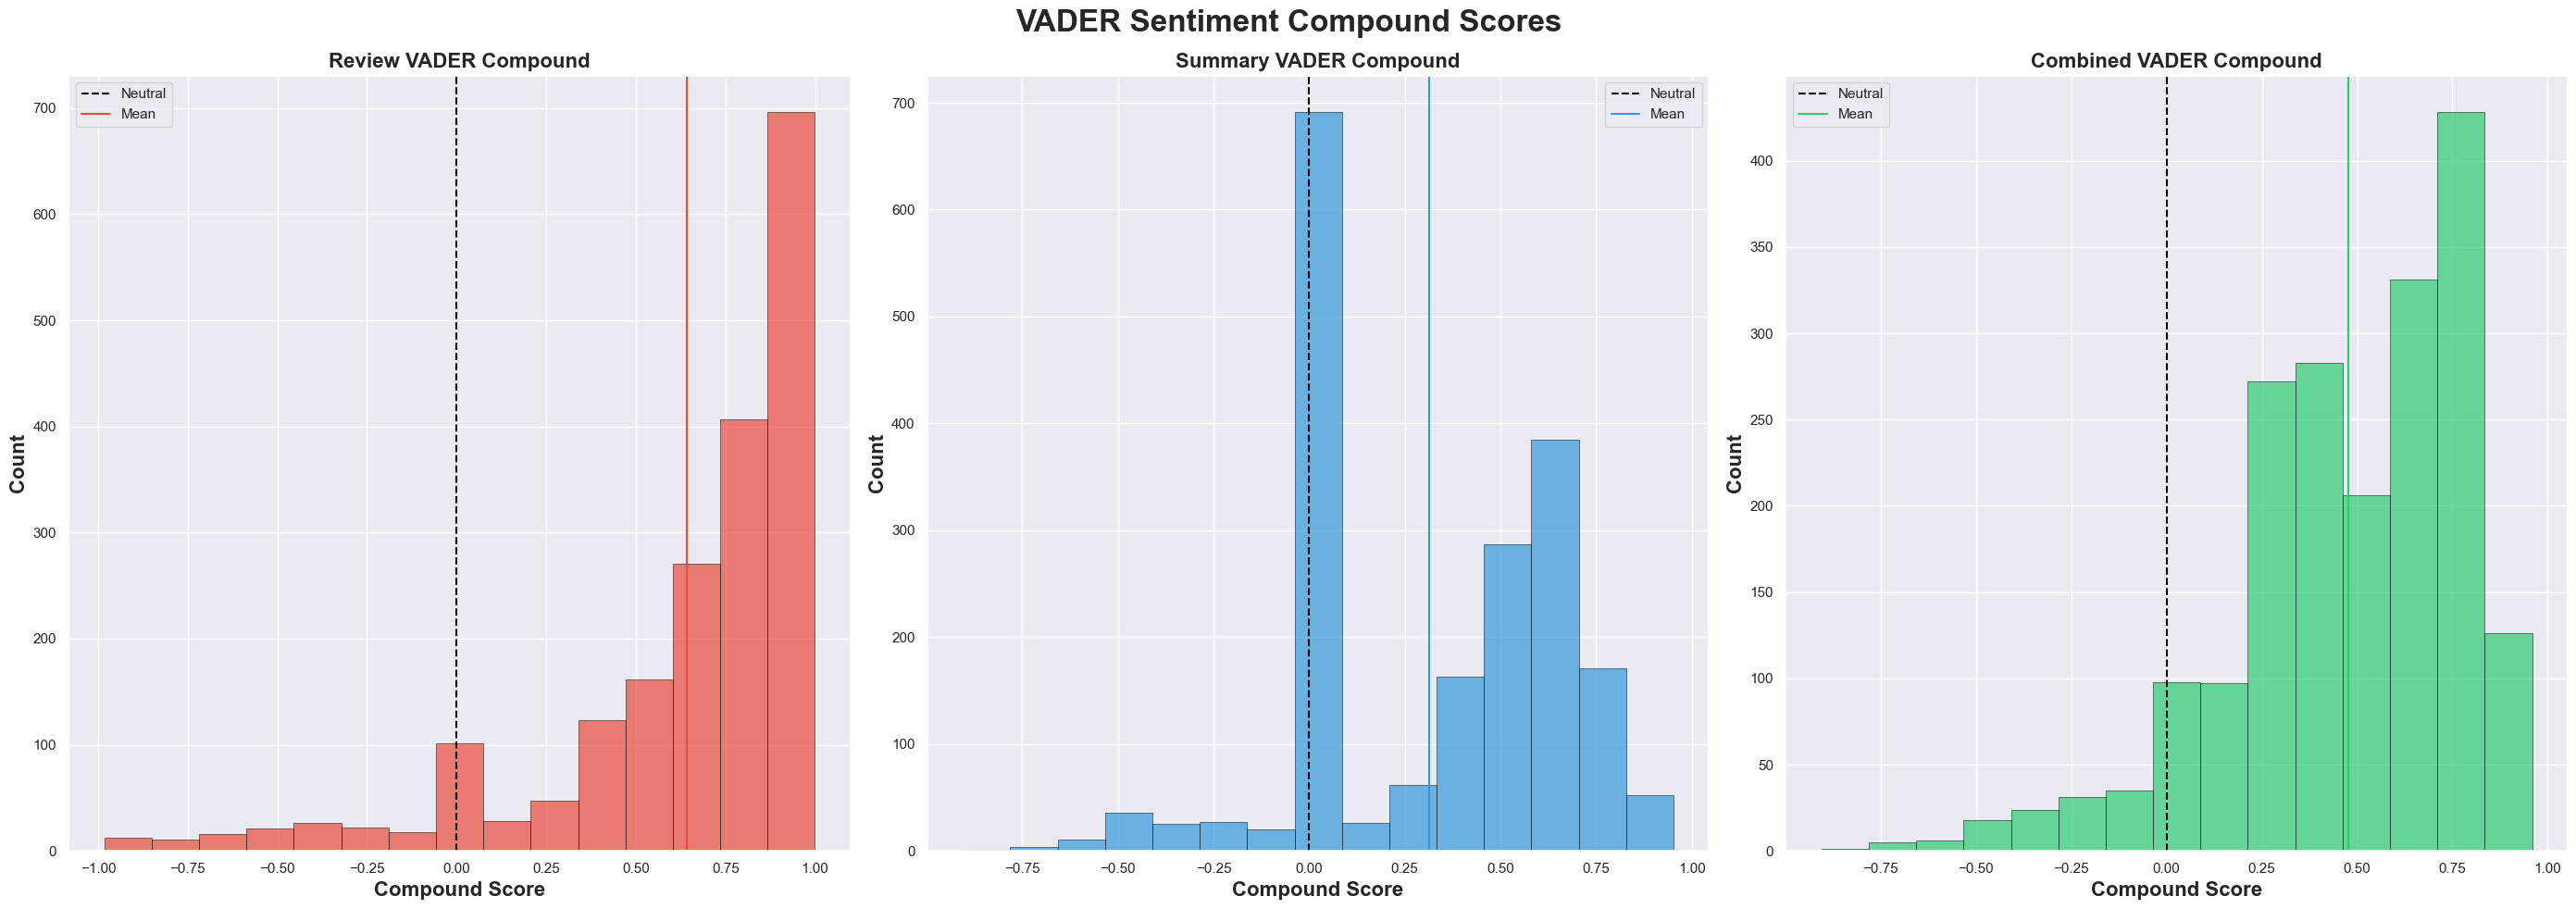

In [169]:
fig, axes = plt.subplots(1, 3, figsize=(28, 10))

# Review compound
axes[0].hist(survey3['review_vader_compound'], bins=15,
             facecolor='#E74C3C', alpha=0.7, edgecolor='black', linewidth=0.5)
axes[0].set_title('Review VADER Compound', fontsize=16, fontweight='bold')
axes[0].set_xlabel('Compound Score', fontsize=16,fontweight='bold')
axes[0].set_ylabel('Count', fontsize=16, fontweight='bold')
axes[0].axvline(x=0, color='black', linestyle='--', linewidth=1.5, label='Neutral')
axes[0].axvline(survey3['review_vader_compound'].mean(), 
                color='#E74C3C', linestyle='-', linewidth=1.5, label='Mean')
axes[0].legend()

# Summary compound
axes[1].hist(survey3['summary_vader_compound'], bins=15,
             facecolor='#3498DB', alpha=0.7, edgecolor='black', linewidth=0.5)
axes[1].set_title('Summary VADER Compound', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Compound Score', fontsize=16, fontweight='bold')
axes[1].set_ylabel('Count', fontsize=16, fontweight='bold')
axes[1].axvline(x=0, color='black', linestyle='--', linewidth=1.5, label='Neutral')
axes[1].axvline(survey3['summary_vader_compound'].mean(), 
                color='#3498DB', linestyle='-', linewidth=1.5, label='Mean')
axes[1].legend()

# Combined compound
axes[2].hist(survey3['combined_vader_compound'], bins=15,
             facecolor='#2ECC71', alpha=0.7, edgecolor='black', linewidth=0.5)
axes[2].set_title('Combined VADER Compound', fontsize=16, fontweight='bold')
axes[2].set_xlabel('Compound Score', fontsize=16, fontweight='bold')
axes[2].set_ylabel('Count', fontsize=16, fontweight='bold')
axes[2].axvline(x=0, color='black', linestyle='--', linewidth=1.5, label='Neutral')
axes[2].axvline(survey3['combined_vader_compound'].mean(), 
                color='#2ECC71', linestyle='-', linewidth=1.5, label='Mean')
axes[2].legend()

plt.suptitle('VADER Sentiment Compound Scores', fontsize=24, fontweight='bold')
plt.tight_layout()
plt.savefig('vader_sentiment_analysis.png', dpi=300)
plt.show()

#### Visualise sentiment label distribution

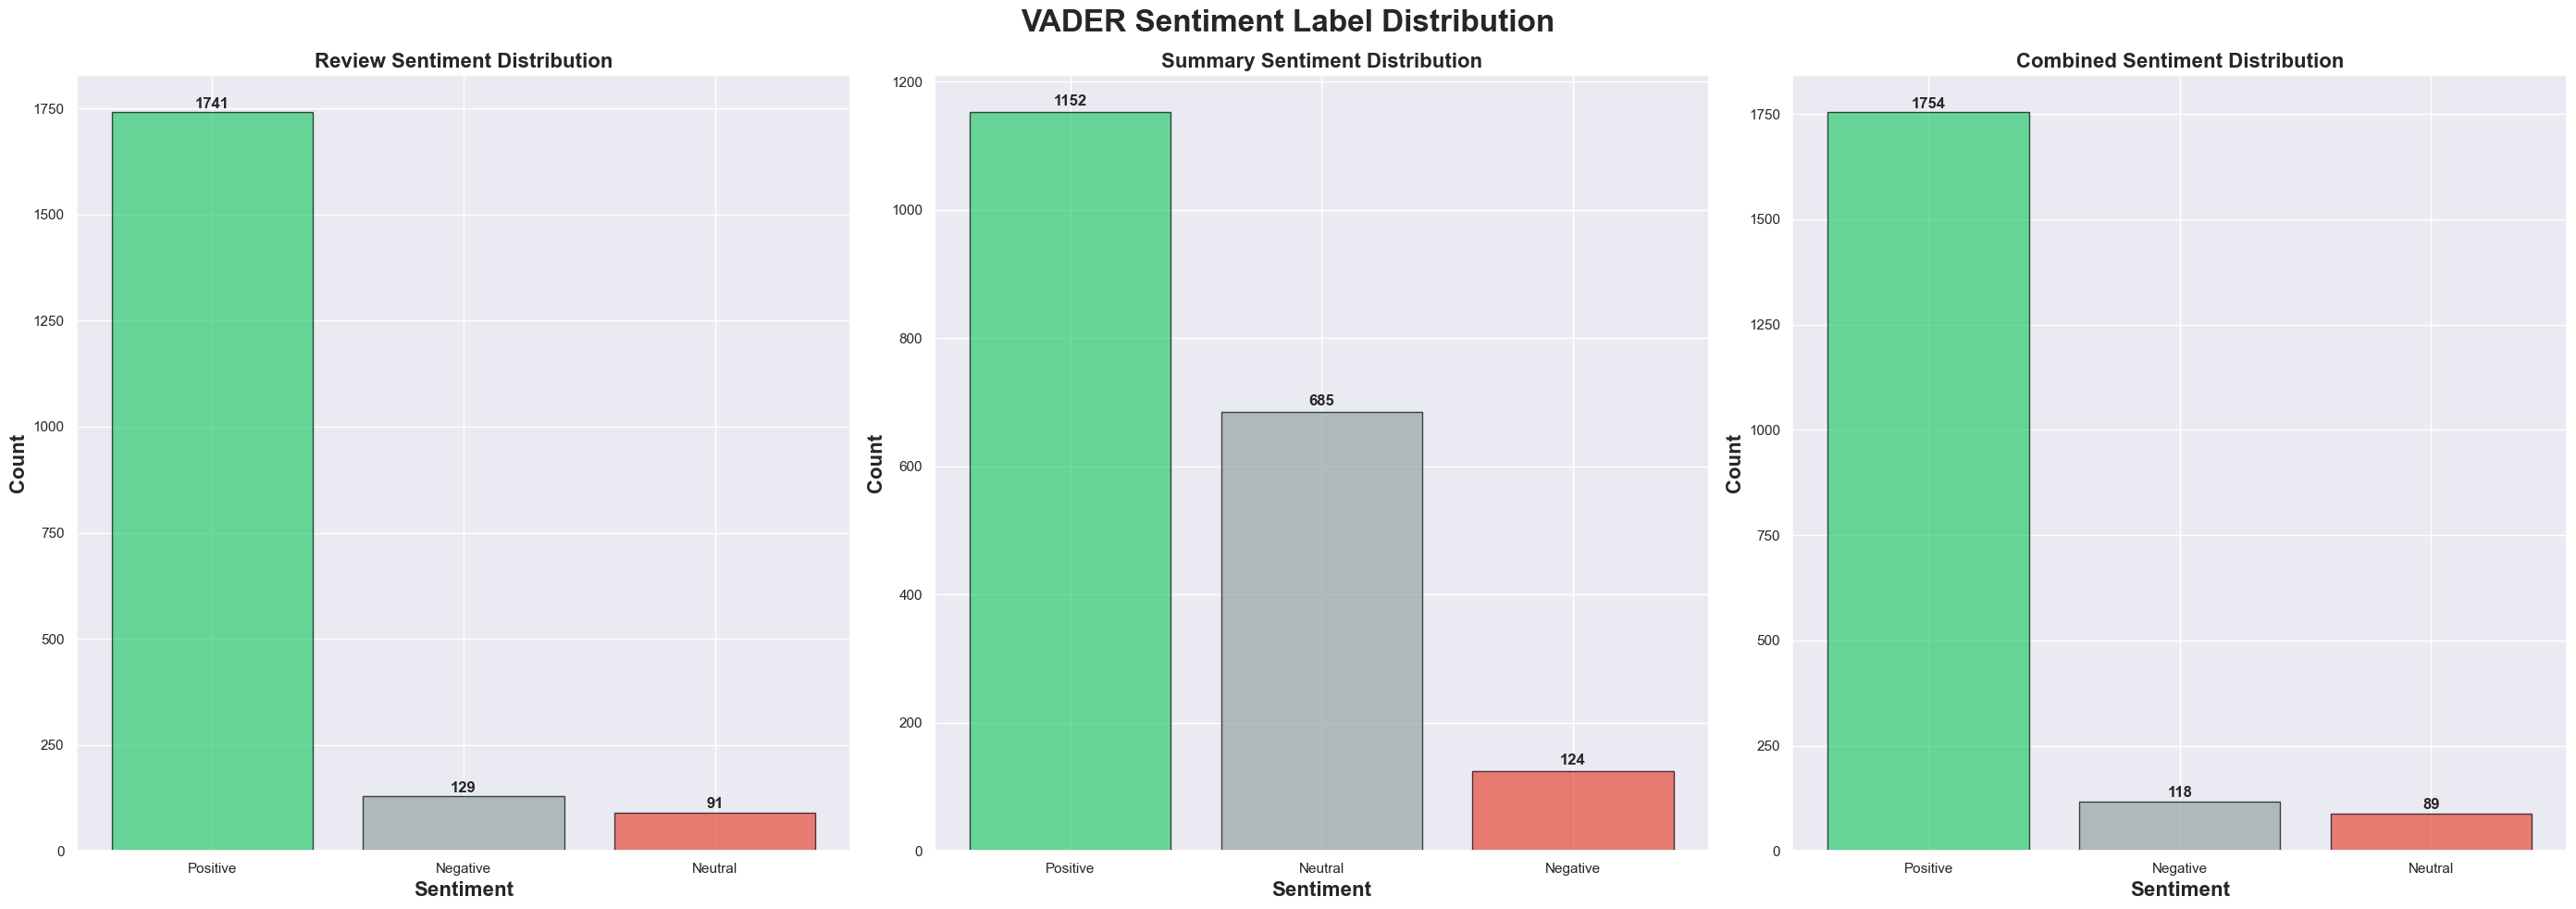

In [171]:
fig, axes = plt.subplots(1, 3, figsize=(28, 10))

colors = ['#2ECC71', '#95A5A6', '#E74C3C']  # positive, neutral, negative

for ax, col, title in zip(axes, 
                           ['review_vader_label', 'summary_vader_label', 'combined_vader_label'],
                           ['Review', 'Summary', 'Combined']):
    counts = survey3[col].value_counts()
    bars = ax.bar(counts.index, counts.values, color=colors, edgecolor='black', alpha=0.7)
    ax.set_title(f'{title} Sentiment Distribution', fontsize=16, fontweight='bold')
    ax.set_xlabel('Sentiment', fontsize=16, fontweight='bold')
    ax.set_ylabel('Count', fontsize=16, fontweight='bold')
    # Add count labels on top of bars
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                str(int(bar.get_height())), ha='center', fontsize=12, fontweight='bold')

plt.suptitle('VADER Sentiment Label Distribution', fontsize=24, fontweight='bold')
plt.tight_layout()
plt.savefig('vader_sentiment_label_distribution.png', dpi=300)
plt.show()

In [183]:
# Top 20 most negative reviews
negative_vader = survey3.nsmallest(20, 'combined_vader_compound')[[
     'summary','review', 
     'combined_vader_compound',
     'combined_vader_label']]

# View with wider columns
negative_vader.style.set_properties(
    subset=['review','summary'], **{'width': '1200px'})

In [184]:
# Top 20 most positive reviews
positive_vader = survey3.nlargest(20, 'combined_vader_compound')[
    ['summary', 'review',
     'combined_vader_compound',
     'combined_vader_label']]

# View with wider columns
positive_vader.style.set_properties(
    subset=['review', 'summary'], **{'width': '1200px'})

#### Insights from Vader Sentiment Analysis 

- The results of 20 negative and 20 positive reviews using VaderSentiment and TextBlob are slightly different, however the overall theme from findings are quite similar.

- Top 20 most positive reviews: 1741 reviews: 88.8% of reviews are considered positive: customers are generally quite satisfied with their purchases

+ great value for money: price satisfaction
+ gift purchases:  major purchase purpose
+ fun and enjoyment: entertainment value is high
+ age inclusivity
+ educational/therapeutic: "great for playing great for creative workshops"

- Top 20 most negative reviews: 129 reviews: 6.6%
+ Product quality: ""crappy cardboard", "bad quality all made of paper", "defective product": Material quality is top complaint
+ Disappointment: "a disappointing coop game"
+ Poor value: "money trap", "not worth the money"
+ Not interested enough

-> VADER captured better those reviews with stronger negativity and short summaries

+ Review 872 scored -0.905 — the most negative in the dataset — contained multiple strong negative words ("crappy", "disgusting", "shame") which VADER detected very accurately
+ Some cases where misclassification might appear such as review 1766 "ball of whacks very useful for pain management" - might suggest a therapeutic product but flagged as "negative"

- Findings:
+ Value for money is the biggest positive driver — appearing consistently across top positive reviews.
+ Quality and disappointment are the biggest negative drivers - particularly material quality and unmet expectations.